# sc-profiles QC check

**Question:** are the single-cell profiles good enough to use, or do we need to change the CellProfiler settings and run it again?

**Answer: yes, we need to change the CellProfiler settings and run it again.**

The images are good. The problem is segmentation in both cell lines (CL1 and CL2):

- **Nuclei are cut into pieces.** In the sampled control images, 18 to 24% of CL1 objects and 41 to 54% of CL2 objects are pieces of one nucleus.
- **Cell outlines are too small and ragged.** They hold only 54 to 64% of the AGP signal in CL2, and 79 to 84% in CL1.
- **There is still real signal.** Random DMSO groups behave as they should, and TGFβ1 replicates well. So the experiment worked, and a new run should give cleaner data.

Sections 10 and 11 give the full scorecard and the settings to change.

## How to read this notebook

Each section follows the same pattern:

- **What we check**: the question, in one line.
- **Why it matters**: what goes wrong later if this check fails.
- **What good looks like**: the limit for a pass.
- **What we found**: the result and what it means.

We explain *what* we check and *why*. We do not explain how each method works.

**Words used in this notebook**

| Word | Meaning |
|---|---|
| Site | One image position in a well. Each well has 9 sites. |
| Feature | One number that CellProfiler measures for a cell, such as nucleus area. |
| Profile | The set of all features for one cell, site or well. |
| Segmentation | Finding the outline of each nucleus and cell in an image. |
| Control well | A well with DMSO only, so no compound and no ligand. |
| Replicate wells | Wells that received the same treatment. |
| Median absolute deviation (MAD) | A measure of spread that outliers do not distort. |
| CL1, CL2 | The two cell lines on each plate. |
| DNA, RNA, AGP, ER, Mito | The 5 stained channels. AGP marks actin, the Golgi and the cell membrane. ER is the endoplasmic reticulum. Mito is the mitochondria. |
| PASS, WARN, FAIL | The grades of a check, based on the limits below. |

## Setup

Paths and settings are here. The slow steps save their results in `cache_dir`, so later runs take minutes. Delete that folder to rebuild the results.

This notebook needs about 200 GB of memory the first time it runs. Run it with `_run-qc.sbatch`, not on the login node.

In [1]:
import json
import os
import pathlib
from concurrent.futures import ThreadPoolExecutor

n_threads = 16
os.environ["POLARS_MAX_THREADS"] = str(n_threads)
os.environ["OMP_NUM_THREADS"] = str(n_threads)

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
from scipy import ndimage as ndi
from scipy.spatial import ConvexHull
from sklearn.decomposition import PCA
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

In [2]:
seed = 0

profiles_dir = pathlib.Path("../../data/sc-profiles").resolve(strict=True)
metadata_dir = profiles_dir / "metadata"
results_dir = pathlib.Path("../../../../results/PALS-screen-profiles").resolve(strict=True)
images_dir = pathlib.Path("../../../../project-data/PALS-screen-data").resolve(strict=True)

# slow results are saved here; delete the folder to rebuild them
cache_dir = pathlib.Path("../../data/qc-cache").resolve()
cache_dir.mkdir(parents=True, exist_ok=True)

# cells kept per well for the feature checks
cells_per_well = 100
# images per plate and cell line for the segmentation tests on the images
images_per_group = 12

# CellProfiler settings under test (2_analysis.cppipe, IdentifyPrimaryObjects)
nucleus_diameter_range = (20, 80)

channels = ["DNA", "RNA", "AGP", "ER", "Mito"]
channel_wavelength = {"DNA": 405, "RNA": 488, "AGP": 561, "Mito": 638, "ER": 730}

# fixed colors: one color per plate and per cell line in every figure
plate_colors = {"1h": "#2a78d6", "4h": "#eb6834", "24h": "#1baf7a"}
line_colors = {"CL1": "#6250d6", "CL2": "#eda100"}
sequential = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#2a78d6", "#0d366b"])
sns.set_theme(style="ticks", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(-1)
pl.Config.set_tbl_width_chars(170)
pl.Config.set_fmt_str_lengths(50)

polars.config.Config

## Limits for each check

We wrote these limits before we made the final figures, so the result cannot move the limit. However, we had looked at a few images first, so the limits are not fully blind. Most are rules of thumb from image-based profiling, not exact standards. A value in the "warn" range means "look closer", not "failed".

In [3]:
# name: (pass limit, warn limit, "low" if lower is better else "high")
limits = {
    "Missing sites (%)": (0.5, 2, "low"),
    "Sites out of focus (%)": (2, 5, "low"),
    "Sites with over 1% saturated DNA pixels (%)": (2, 5, "low"),
    "Brightness change across the field (max/min)": (1.2, 1.4, "low"),
    "Nuclei near the upper size limit (%)": (0.5, 2, "low"),
    "Nuclei with too little DNA (%)": (10, 20, "low"),
    "Objects that are pieces of a cut nucleus (%)": (2, 5, "low"),
    "DNA signal without a nucleus object (%)": (2, 5, "low"),
    "AGP signal inside cell outlines (%)": (90, 75, "high"),
    "Cells with almost no cytoplasm (%)": (2, 5, "low"),
    "Median cell solidity": (0.85, 0.80, "high"),
    "Replicating treatments (%)": (50, 20, "high"),
    "Replicating DMSO groups (negative control, %)": (10, 20, "low"),
}


def grade(name, value):
    """Return PASS, WARN or FAIL for one check."""
    pass_limit, warn_limit, direction = limits[name]
    sign = 1 if direction == "low" else -1
    if sign * value <= sign * pass_limit:
        return "PASS"
    return "WARN" if sign * value <= sign * warn_limit else "FAIL"


# filled in by each section and shown as a table at the end
scorecard = []


def score(name, value, group="All"):
    """Add one result to the scorecard."""
    scorecard.append({"check": name, "group": group, "value": round(float(value), 2), "grade": grade(name, value)})

## The decision rule

We fixed this rule before the final run.

- **Starting assumption (H0):** the current segmentation is good enough, so we keep the data.
- **Alternative (H1):** the segmentation has a systematic error, so features describe the wrong objects, and we must run CellProfiler again.
- **We reject H0** if a segmentation check (7.2 to 7.5) fails in at least half of the plate and cell line groups, **and** the positive control in 7.4 supports the cause.
- **Controls:** the DNA peaks are the positive control for segmentation. TGFβ1 is the positive control for biology. Random DMSO groups are the negative control for the replicate test.

## 1. The experiment

**What we check:** which plates, wells and treatments we have, and whether the metadata agrees with the data.

**Why it matters:** every later check compares the right wells only if the labels are right.

**What good looks like:** each plate has all expected wells, and the metadata has one clear label per well.

The screen has 3 plates, one for each time point after treatment (1h, 4h and 24h). The plates share one layout.

In [4]:
plate_files = {
    path.stem.split("_")[3]: path
    for path in sorted(profiles_dir.glob("*.parquet"))
}
plate_order = ["1h", "4h", "24h"]
plate_names = {time: plate_files[time].stem for time in plate_order}

platemap = pl.read_csv(metadata_dir / "platemap.csv", infer_schema_length=0).select(
    pl.col("Well").alias("Metadata_Well"),
    pl.col("Compound ID").alias("compound"),
    pl.col("Conc mM").cast(pl.Float64).round(2).alias("compound_stock_mM"),
)

ligands = (
    pl.read_csv(metadata_dir / "ligands.csv", infer_schema_length=0)
    .select(
        pl.col("destination well").alias("well"),
        pl.col("CellLine").alias("ligand_cell_line"),
        pl.col("Treatment").alias("ligand"),
        pl.col("Concentration final").alias("ligand_dose"),
    )
    .with_columns(
        (pl.col("well").str.slice(0, 1) + pl.col("well").str.slice(1).str.zfill(2)).alias("Metadata_Well")
    )
    .drop("well")
)

wells = (
    platemap.join(ligands, on="Metadata_Well", how="left")
    .with_columns(
        pl.col("Metadata_Well").str.slice(0, 1).alias("row"),
        pl.col("Metadata_Well").str.slice(1).cast(pl.Int64).alias("column"),
    )
    .with_columns(
        # the design is mirrored: columns 1-12 are CL1, columns 13-24 are CL2
        pl.when(pl.col("column") <= 12).then(pl.lit("CL1")).otherwise(pl.lit("CL2")).alias("cell_line"),
        (pl.col("row").is_in(["A", "P"]) | pl.col("column").is_in([1, 24])).alias("edge"),
    )
    .with_columns(
        pl.when(pl.col("compound") != "DMSO")
        .then(pl.lit("compound"))
        .when(pl.col("ligand").is_not_null())
        .then(pl.lit("ligand"))
        .otherwise(pl.lit("control"))
        .alias("well_type"),
        pl.when(pl.col("compound") != "DMSO")
        .then(pl.col("compound") + "_" + pl.col("compound_stock_mM").cast(pl.String))
        .when(pl.col("ligand").is_not_null())
        .then(pl.col("ligand") + "_" + pl.col("ligand_dose"))
        .otherwise(pl.lit("DMSO"))
        .alias("treatment"),
    )
)

# the ligand file names the cell line, so it can test the column rule above
mismatch = wells.filter(pl.col("ligand").is_not_null() & (pl.col("ligand_cell_line") != pl.col("cell_line")))
if mismatch.height:
    raise ValueError(f"Cell line rule disagrees with ligands.csv in {mismatch.height} wells")

print(wells.group_by("cell_line", "well_type").agg(pl.len().alias("wells"), pl.col("treatment").n_unique().alias("treatments")).sort("cell_line", "well_type"))

shape: (6, 4)
┌───────────┬───────────┬───────┬────────────┐
│ cell_line ┆ well_type ┆ wells ┆ treatments │
│ ---       ┆ ---       ┆ ---   ┆ ---        │
│ str       ┆ str       ┆ u32   ┆ u32        │
╞═══════════╪═══════════╪═══════╪════════════╡
│ CL1       ┆ compound  ┆ 45    ┆ 15         │
│ CL1       ┆ control   ┆ 129   ┆ 1          │
│ CL1       ┆ ligand    ┆ 18    ┆ 6          │
│ CL2       ┆ compound  ┆ 45    ┆ 15         │
│ CL2       ┆ control   ┆ 129   ┆ 1          │
│ CL2       ┆ ligand    ┆ 18    ┆ 6          │
└───────────┴───────────┴───────┴────────────┘


In [5]:
settings = []
for time in plate_order:
    params = json.loads((images_dir / plate_names[time] / "parameters.json").read_text())
    exposure = {c["Name"]: c["ExposureTime"] for c in params["channels_config"]}
    settings.append(
        {
            "plate": time,
            "cell line in parameters.json": params["cell_line"],
            "objective": params["objective"],
            **{f"{ch} exposure (ms)": exposure[f"Fluorescence {wl} nm Ex"] for ch, wl in channel_wavelength.items()},
        }
    )
pl.DataFrame(settings)

plate,cell line in parameters.json,objective,DNA exposure (ms),RNA exposure (ms),AGP exposure (ms),Mito exposure (ms),ER exposure (ms)
str,str,str,f64,f64,f64,f64,f64
"""1h""","""MDA-MB-231_wt_ko""","""20x (Olympus)""",5.0,7.0,80.0,20.0,100.0
"""4h""","""MDA-MB-231_wt_ko""","""20x (Olympus)""",5.0,7.0,80.0,20.0,100.0
"""24h""","""MDA-MB-231_wt_ko""","""20x (Olympus)""",5.0,7.0,90.0,20.0,200.0


**What we found**

- The design has 5 compounds at 3 doses and 2 ligands (TGFβ1 and IL6) at 3 doses, with 3 replicate wells per cell line on each plate. Each cell line has 127 imaged control wells.
- **Columns 1 to 12 are CL1 and columns 13 to 24 are CL2.** The ligand file confirms this rule for all 36 ligand wells. The compound wells follow the same mirrored layout. So cell line and plate side cannot be separated.
- **The 24h plate used longer exposures:** 200 ms instead of 100 ms for ER, and 90 ms instead of 80 ms for AGP. This means that time and exposure cannot be separated, so raw brightness must not be compared between the 24h plate and the others. We avoid this problem by comparing each well with the DMSO wells of its own plate.
- **`parameters.json` says the cell line is `MDA-MB-231_wt_ko`**, but the plate names say Panc1 and hPSC. This is probably an old value that nobody updated, but we cannot confirm it from the data. We also do not have a record of which line is CL1 and which is CL2.

## 2. Load the data

We use two levels of the data:

- **Every cell, a few columns.** About 30 columns for all 4.4 million cells, to check counts, sizes and shapes.
- **Summaries of all columns.** The median profile of each site, and a random sample of cells from each well.

In [6]:
key_columns = [
    "Metadata_Well", "Metadata_Site", "Metadata_Acquisition",
    "Nuclei_AreaShape_Area", "Nuclei_AreaShape_EquivalentDiameter", "Nuclei_AreaShape_Solidity",
    "Cells_AreaShape_Area", "Cells_AreaShape_Solidity", "Cytoplasm_AreaShape_Area",
    "Nuclei_Intensity_IntegratedIntensity_CorrDNA",
    "Nuclei_Location_Center_X", "Nuclei_Location_Center_Y",
    "Cells_Children_Cytoplasm_Count",
]
key_columns += [f"Nuclei_Intensity_MeanIntensity_Corr{ch}" for ch in channels]
key_columns += [f"Cytoplasm_Intensity_MeanIntensity_Corr{ch}" for ch in channels]
key_columns += [f"Cells_Intensity_MeanIntensity_Corr{ch}" for ch in channels]

cells = pl.concat(
    [pl.read_parquet(plate_files[t], columns=key_columns).with_columns(pl.lit(t).alias("plate")) for t in plate_order]
).join(wells.select("Metadata_Well", "cell_line", "well_type", "treatment"), on="Metadata_Well", how="left")
print(f"{cells.height:,} cells")

4,377,843 cells


In [7]:
all_columns = pl.scan_parquet(plate_files["1h"]).collect_schema().names()
image_columns = [
    c for c in all_columns
    if c.startswith(("Image_Count", "Image_ImageQuality", "Image_Threshold", "Image_ModuleError"))
    or c.startswith("Image_Intensity_MeanIntensity")
]

images = pl.concat(
    [
        pl.scan_parquet(plate_files[t])
        .select(["Metadata_Well", "Metadata_Site", "Metadata_Acquisition", *image_columns])
        .unique("Metadata_Acquisition")
        .collect()
        .with_columns(pl.lit(t).alias("plate"))
        for t in plate_order
    ]
).join(wells, on="Metadata_Well", how="left")
images.select(pl.len().alias("sites"))

sites
u32
10259


In [8]:
# measurements of cell biology; position, object numbers and neighbor IDs are bookkeeping
compartments = ("Cells_", "Cytoplasm_", "Nuclei_")
bookkeeping = ("Location", "Number", "Parent", "Children", "Center", "BoundingBox", "Orientation", "ClosestObjectNumber")
features = [
    c for c in all_columns
    if c.startswith(compartments) and not any(word in c for word in bookkeeping)
]
print(f"{len(features)} features out of {len(all_columns)} columns")


def build_summaries(time):
    """Save the median profile per site and a random sample of cells for one plate."""
    site_path = cache_dir / f"site_profiles_{time}.parquet"
    sample_path = cache_dir / f"cell_sample_{time}.parquet"
    if site_path.exists() and sample_path.exists():
        return
    table = pl.read_parquet(plate_files[time], columns=["Metadata_Well", "Metadata_Site", *features])
    table.group_by("Metadata_Well", "Metadata_Site").agg(
        pl.len().alias("n_cells"), pl.col(features).median()
    ).write_parquet(site_path)
    table.filter(
        pl.int_range(pl.len()).shuffle(seed=seed).over("Metadata_Well") < cells_per_well
    ).write_parquet(sample_path)


for time in plate_order:
    build_summaries(time)

site_profiles = pl.concat(
    [pl.read_parquet(cache_dir / f"site_profiles_{t}.parquet").with_columns(pl.lit(t).alias("plate")) for t in plate_order]
).join(wells, on="Metadata_Well", how="left")
cell_sample = pl.concat([pl.read_parquet(cache_dir / f"cell_sample_{t}.parquet") for t in plate_order])
print(site_profiles.shape, cell_sample.shape)

3041 features out of 4053 columns


(10259, 3056) (114000, 3043)


## 3. Is the data complete?

**What we check:** whether every site was processed, and whether any CellProfiler step reported an error.

**Why it matters:** missing sites reduce the cells in a well. Hidden errors can produce wrong numbers without any warning.

**What good looks like:** no more than 0.5% of sites missing, and no module errors.

In [9]:
expected_sites = wells.filter(
    ~pl.col("Metadata_Well").is_in(["A01", "A24", "P01", "P24"])
).height * 9
completeness = (
    images.group_by("plate")
    .agg(pl.len().alias("sites"))
    .with_columns((100 * (1 - pl.col("sites") / expected_sites)).alias("missing_pct"))
    .sort("plate")
)
print(f"Expected sites per plate: {expected_sites} (380 wells; the 4 corner wells were not imaged)")
print(completeness)

for time in plate_order:
    site_counts = images.filter(pl.col("plate") == time).group_by("Metadata_Well").agg(pl.len().alias("n"))
    print(time, "wells without 9 sites:", site_counts.filter(pl.col("n") != 9).rows())

error_columns = [c for c in images.columns if "ModuleError" in c]
print("Sites with a module error:", images.select(pl.any_horizontal(pl.col(error_columns) > 0).sum()).item())

score("Missing sites (%)", completeness["missing_pct"].max())

Expected sites per plate: 3420 (380 wells; the 4 corner wells were not imaged)
shape: (3, 3)
┌───────┬───────┬─────────────┐
│ plate ┆ sites ┆ missing_pct │
│ ---   ┆ ---   ┆ ---         │
│ str   ┆ u32   ┆ f64         │
╞═══════╪═══════╪═════════════╡
│ 1h    ┆ 3420  ┆ 0.0         │
│ 24h   ┆ 3419  ┆ 0.02924     │
│ 4h    ┆ 3420  ┆ 0.0         │
└───────┴───────┴─────────────┘
1h wells without 9 sites: []
4h wells without 9 sites: []
24h wells without 9 sites: [('N12', 8)]
Sites with a module error: 0


**What we found**

**Pass.** The data is complete. Only 1 of 10,260 sites is missing (well N12, 24h plate), and no CellProfiler module reported an error. The data holds 4,377,843 cells.

## 4. Are the images sharp, and are they too bright?

**What we check:** focus and saturation, for each channel and site.

**Why it matters:** a blurred image changes texture and granularity features, and it can look like a drug effect. A saturated pixel hides real differences in brightness, because the camera cannot record any higher value.

**What good looks like:**

- No more than 2% of sites out of focus. We call a site out of focus when its focus measure is more than 5 MADs below its plate and cell line.
- No more than 2% of sites have over 1% saturated DNA pixels.

shape: (6, 3)
┌───────┬───────────┬──────────┐
│ plate ┆ cell_line ┆ pct      │
│ ---   ┆ ---       ┆ ---      │
│ str   ┆ str       ┆ f64      │
╞═══════╪═══════════╪══════════╡
│ 1h    ┆ CL1       ┆ 0.994152 │
│ 24h   ┆ CL1       ┆ 0.0      │
│ 4h    ┆ CL1       ┆ 0.116959 │
│ 1h    ┆ CL2       ┆ 0.467836 │
│ 24h   ┆ CL2       ┆ 1.637427 │
│ 4h    ┆ CL2       ┆ 0.584795 │
└───────┴───────────┴──────────┘


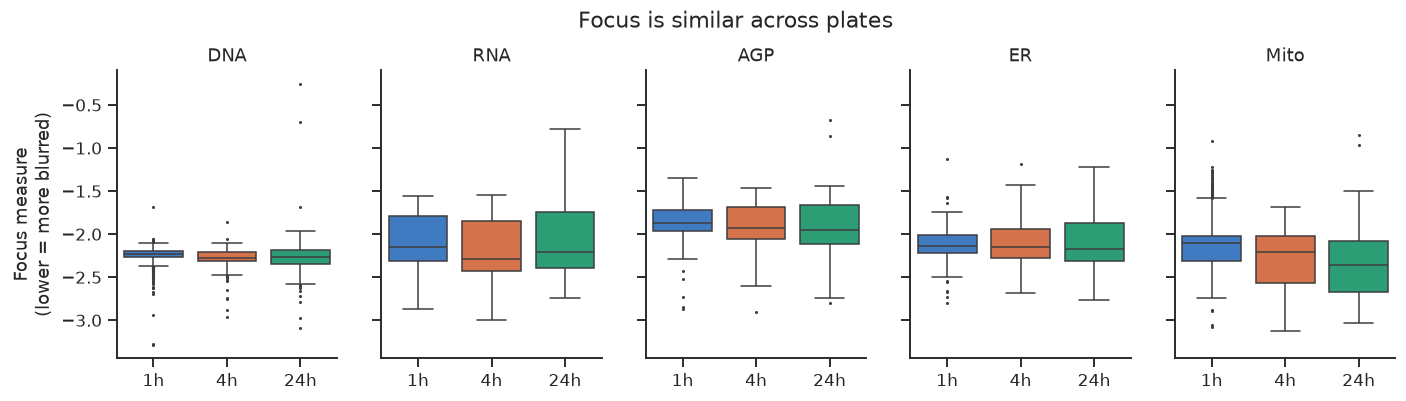

In [10]:
def robust_z(column, by):
    """Distance from the group median, in units of the group's spread."""
    median = pl.col(column).median().over(by)
    mad = (pl.col(column) - median).abs().median().over(by) * 1.4826
    return (pl.col(column) - median) / mad


focus_rows = []
for ch in channels:
    column = f"Image_ImageQuality_PowerLogLogSlope_{ch}"
    focus_rows.append(
        images.select(
            "plate", "cell_line", "Metadata_Acquisition", "Metadata_Well",
            pl.lit(ch).alias("channel"),
            pl.col(column).alias("slope"),
            pl.col(f"Image_ImageQuality_FocusScore_{ch}").alias("focus_score"),
            robust_z(column, ["plate", "cell_line"]).alias("z"),
        )
    )
focus = pl.concat(focus_rows)
out_of_focus = focus.group_by("plate", "cell_line").agg(
    (100 * pl.col("Metadata_Acquisition").filter(pl.col("z") < -5).n_unique() / pl.col("Metadata_Acquisition").n_unique()).alias("pct")
).sort("cell_line", "plate")
print(out_of_focus)

fig, axes = plt.subplots(1, 5, figsize=(15, 3.4), sharey=True)
for ax, ch in zip(axes, channels):
    sns.boxplot(
        data=focus.filter(pl.col("channel") == ch).to_pandas(), x="plate", y="slope", hue="plate",
        order=plate_order, palette=plate_colors, ax=ax, fliersize=1, legend=False,
    )
    ax.set_title(ch)
    ax.set_xlabel("")
axes[0].set_ylabel("Focus measure\n(lower = more blurred)")
fig.suptitle("Focus is similar across plates", y=1.04)
plt.show()

for row in out_of_focus.iter_rows(named=True):
    score("Sites out of focus (%)", row["pct"], f"{row['plate']} {row['cell_line']}")

In [11]:
# PercentMaximal counts pixels at the image's own maximum, so it only means saturation
# when that maximum is close to the top of the camera range
saturation = pl.concat(
    [
        images.select(
            "plate", "cell_line", pl.lit(ch).alias("channel"),
            pl.when(pl.col(f"Image_ImageQuality_MaxIntensity_{ch}") >= 0.99)
            .then(pl.col(f"Image_ImageQuality_PercentMaximal_{ch}"))
            .otherwise(0.0)
            .alias("saturated_pct"),
        )
        for ch in channels
    ]
)
saturation_table = (
    saturation.group_by("channel", "plate")
    .agg(
        pl.col("saturated_pct").median().round(4).alias("median_pct"),
        pl.col("saturated_pct").max().round(2).alias("max_pct"),
        (100 * (pl.col("saturated_pct") > 1).mean()).round(2).alias("sites_over_1pct"),
    )
    .sort("channel", "plate")
)
print(saturation_table)

for row in saturation_table.filter(pl.col("channel") == "DNA").iter_rows(named=True):
    score("Sites with over 1% saturated DNA pixels (%)", row["sites_over_1pct"], row["plate"])

shape: (15, 5)
┌─────────┬───────┬────────────┬─────────┬─────────────────┐
│ channel ┆ plate ┆ median_pct ┆ max_pct ┆ sites_over_1pct │
│ ---     ┆ ---   ┆ ---        ┆ ---     ┆ ---             │
│ str     ┆ str   ┆ f64        ┆ f64     ┆ f64             │
╞═════════╪═══════╪════════════╪═════════╪═════════════════╡
│ AGP     ┆ 1h    ┆ 0.0003     ┆ 0.09    ┆ 0.0             │
│ AGP     ┆ 24h   ┆ 0.0007     ┆ 1.98    ┆ 0.03            │
│ AGP     ┆ 4h    ┆ 0.0001     ┆ 0.07    ┆ 0.0             │
│ DNA     ┆ 1h    ┆ 0.0363     ┆ 11.37   ┆ 0.2             │
│ DNA     ┆ 24h   ┆ 0.0747     ┆ 3.85    ┆ 0.18            │
│ DNA     ┆ 4h    ┆ 0.0534     ┆ 1.36    ┆ 0.12            │
│ ER      ┆ 1h    ┆ 0.001      ┆ 0.56    ┆ 0.0             │
│ ER      ┆ 24h   ┆ 0.0063     ┆ 0.72    ┆ 0.0             │
│ ER      ┆ 4h    ┆ 0.0012     ┆ 0.19    ┆ 0.0             │
│ Mito    ┆ 1h    ┆ 0.0419     ┆ 0.9     ┆ 0.0             │
│ Mito    ┆ 24h   ┆ 0.0312     ┆ 6.83    ┆ 3.57            │
│ Mito   

**What we found**

**Pass.** Focus is stable: at most 1.64% of sites are out of focus in any group. DNA saturation is rare, at most 0.2% of sites. The Mito channel on the 24h plate has the most saturation, with 3.57% of sites over 1%. This does not change the decision, but those sites deserve a filter later.

The images themselves are not the cause of the problems we find below.

## 5. Are the cell numbers healthy and even across the plate?

**What we check:** the number of cells per well, shown as a map of each plate.

**Why it matters:** cell density changes cell shape and many other features. If one plate region has fewer cells, its profiles differ for a reason that has nothing to do with the treatment.

**What good looks like:** similar numbers across control wells, with no clear pattern by row or column. We expect more cells at later time points, because cells divide.

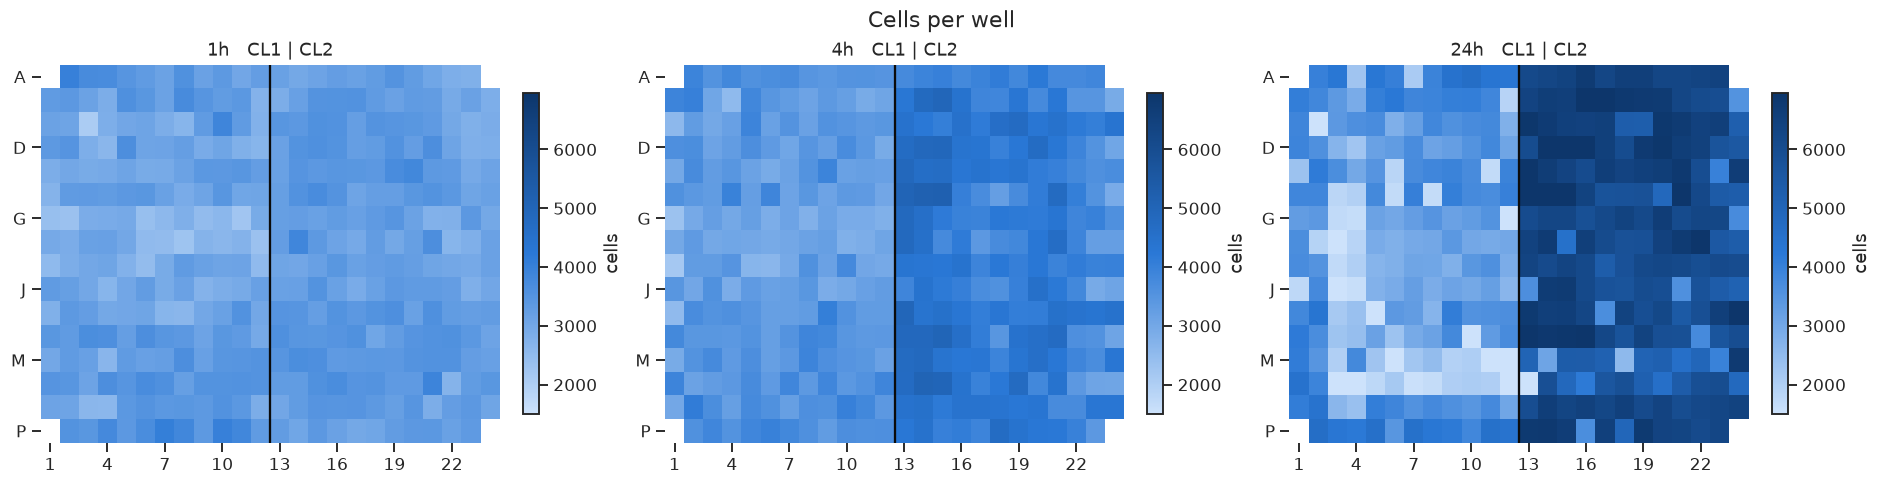

In [12]:
def plate_heatmaps(table, value, title, cmap=sequential, center=None, label=None):
    """Draw one map per plate. The line in the middle separates the two cell lines."""
    rows = list("ABCDEFGHIJKLMNOP")
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.3), constrained_layout=True)
    finite = table[value].drop_nans().drop_nulls()
    vmin, vmax = (None, None) if center is not None else (finite.quantile(0.01), finite.quantile(0.99))
    for ax, time in zip(axes, plate_order):
        grid = np.full((16, 24), np.nan)
        for row, column, val in table.filter(pl.col("plate") == time).select("row", "column", value).iter_rows():
            grid[rows.index(row), column - 1] = val
        mesh = ax.imshow(grid, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
        if center is not None:
            limit = np.nanquantile(np.abs(grid - center), 0.99)
            mesh.set_clim(center - limit, center + limit)
        ax.axvline(11.5, color="#0b0b0b", lw=1.5)
        ax.set_title(f"{time}   CL1 | CL2")
        ax.set_xticks(range(0, 24, 3), range(1, 25, 3))
        ax.set_yticks(range(0, 16, 3), rows[::3])
        ax.spines[:].set_visible(False)
        fig.colorbar(mesh, ax=ax, shrink=0.85, label=label)
    fig.suptitle(title)
    plt.show()


well_counts = (
    images.group_by("plate", "Metadata_Well")
    .agg(
        pl.col("Image_Count_Cells").sum().alias("cells"),
        pl.first("row", "column", "cell_line", "well_type", "edge", "treatment"),
    )
)
plate_heatmaps(well_counts, "cells", "Cells per well", label="cells")

In [13]:
control_counts = well_counts.filter(pl.col("well_type") == "control")
print(
    control_counts.group_by("plate", "cell_line")
    .agg(
        pl.len().alias("wells"),
        pl.col("cells").median().alias("median_cells"),
        pl.col("cells").min().alias("min"),
        pl.col("cells").max().alias("max"),
        (100 * pl.col("cells").std() / pl.col("cells").mean()).round(1).alias("cv_pct"),
        (pl.col("cells").filter(pl.col("edge")).median() / pl.col("cells").filter(~pl.col("edge")).median()).round(2).alias("edge_vs_inner"),
    )
    .sort("cell_line", "plate")
)
print(well_counts.sort("cells").head(10).select("plate", "Metadata_Well", "cells", "treatment"))

shape: (6, 8)
┌───────┬───────────┬───────┬──────────────┬────────┬────────┬────────┬───────────────┐
│ plate ┆ cell_line ┆ wells ┆ median_cells ┆ min    ┆ max    ┆ cv_pct ┆ edge_vs_inner │
│ ---   ┆ ---       ┆ ---   ┆ ---          ┆ ---    ┆ ---    ┆ ---    ┆ ---           │
│ str   ┆ str       ┆ u32   ┆ f64          ┆ f64    ┆ f64    ┆ f64    ┆ f64           │
╞═══════╪═══════════╪═══════╪══════════════╪════════╪════════╪════════╪═══════════════╡
│ 1h    ┆ CL1       ┆ 127   ┆ 3136.0       ┆ 2060.0 ┆ 4002.0 ┆ 12.3   ┆ 1.08          │
│ 24h   ┆ CL1       ┆ 127   ┆ 3495.0       ┆ 1483.0 ┆ 4617.0 ┆ 23.8   ┆ 1.3           │
│ 4h    ┆ CL1       ┆ 127   ┆ 3335.0       ┆ 2174.0 ┆ 4036.0 ┆ 10.7   ┆ 1.07          │
│ 1h    ┆ CL2       ┆ 127   ┆ 3277.0       ┆ 2660.0 ┆ 3898.0 ┆ 7.3    ┆ 0.95          │
│ 24h   ┆ CL2       ┆ 127   ┆ 6276.0       ┆ 3601.0 ┆ 7348.0 ┆ 9.8    ┆ 1.01          │
│ 4h    ┆ CL2       ┆ 127   ┆ 4212.0       ┆ 2895.0 ┆ 5171.0 ┆ 11.0   ┆ 0.93          │
└───────┴─────────

**What we found**

**Look closer at the 24h plate.**

- At 1h and 4h, control wells are even (variation of 7 to 12%), and edge wells match inner wells (ratio 0.93 to 1.08).
- On the 24h plate, CL1 has clear patches with few cells, in columns 3 and 4 (rows F to N) and across rows M and N. This is also true in control wells: the variation is 23.8%, and edge wells have 1.3 times more cells than inner wells. The pattern suggests a problem with seeding or handling, not a treatment effect.
- CL2 appears to double from 3,277 to 6,276 cells per well, while CL1 grows only from 3,136 to 3,495. **Do not trust the CL2 number yet.** Section 7 shows that many CL2 "cells" are pieces of nuclei, so the true count is lower.

## 6. Is the brightness even across each image?

**What we check:** cell brightness at different positions in the image, after illumination correction. We use control wells only.

**Why it matters:** microscopes light the centre of an image more strongly than the corners. Without a good correction, a cell's brightness depends on where it sits in the image.

**What good looks like:** the brightest and dimmest parts of a 5 by 5 grid differ by a factor below 1.2.

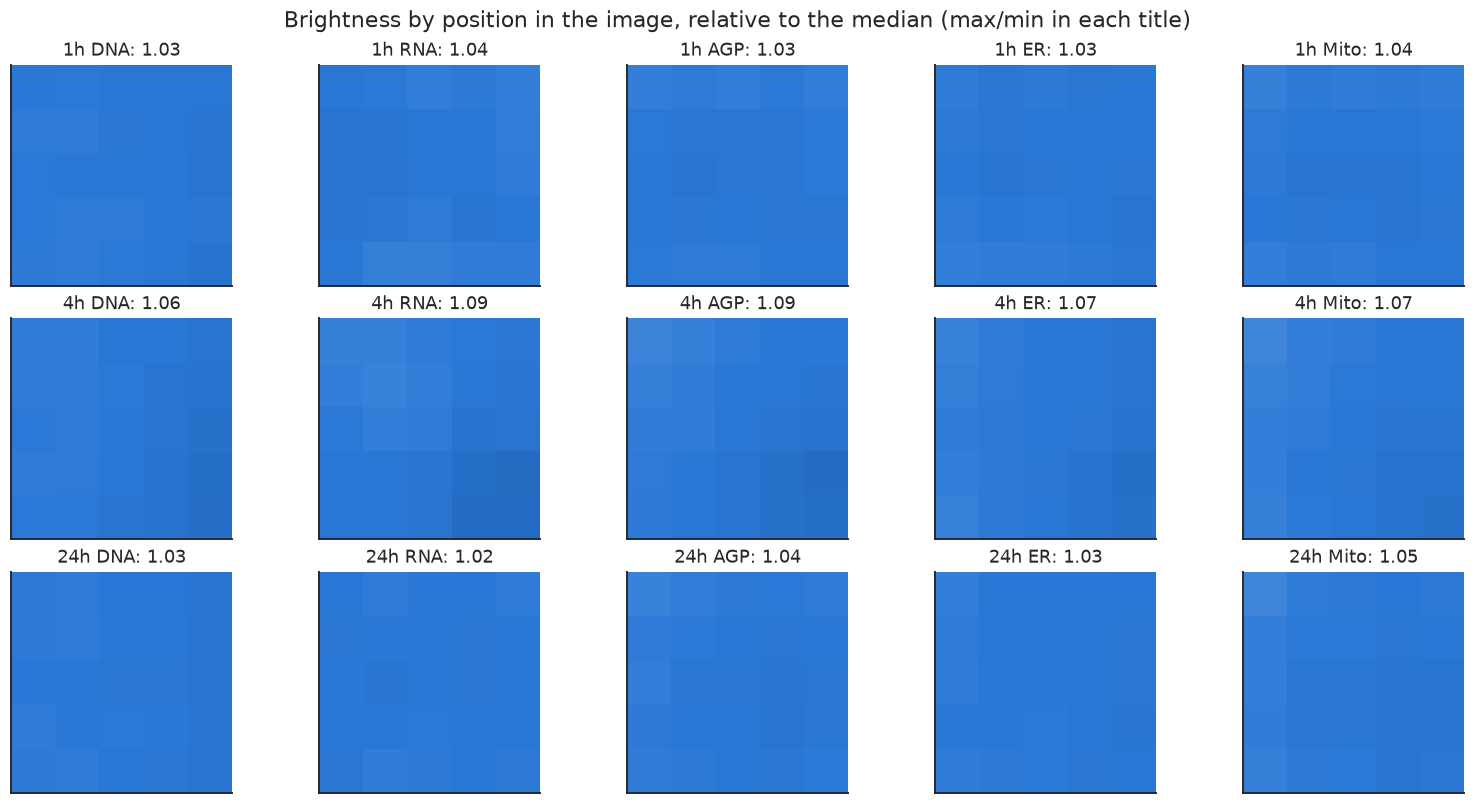

In [14]:
grid_bins = 5
image_size = 2500

position = cells.filter(pl.col("well_type") == "control").with_columns(
    (pl.col("Nuclei_Location_Center_X") * grid_bins / image_size).floor().clip(0, grid_bins - 1).alias("x_bin"),
    (pl.col("Nuclei_Location_Center_Y") * grid_bins / image_size).floor().clip(0, grid_bins - 1).alias("y_bin"),
)

ratios = []
fig, axes = plt.subplots(3, 5, figsize=(14, 7.2), constrained_layout=True)
for i, time in enumerate(plate_order):
    for j, ch in enumerate(channels):
        grid = (
            position.filter(pl.col("plate") == time)
            .group_by("y_bin", "x_bin")
            .agg(pl.col(f"Cells_Intensity_MeanIntensity_Corr{ch}").median().alias("value"))
            .sort("y_bin", "x_bin")["value"].to_numpy().reshape(grid_bins, grid_bins)
        )
        ratios.append({"plate": time, "channel": ch, "ratio": grid.max() / grid.min()})
        axes[i, j].imshow(grid / np.median(grid), cmap=sequential, vmin=0.7, vmax=1.3)
        axes[i, j].set(xticks=[], yticks=[], title=f"{time} {ch}: {grid.max() / grid.min():.2f}")
fig.suptitle("Brightness by position in the image, relative to the median (max/min in each title)")
plt.show()

ratios = pl.DataFrame(ratios)
for row in ratios.group_by("channel").agg(pl.col("ratio").max()).sort("channel").iter_rows(named=True):
    score("Brightness change across the field (max/min)", row["ratio"], row["channel"])

**What we found**

**Pass.** The brightest and dimmest parts of the image differ by a factor of at most 1.09. The illumination correction works, and it needs no change.

## 7. Did CellProfiler find the nuclei and cells correctly?

This is the most important section for our question. Features can only be right if the outlines are right. A nucleus cut in two gives two false "cells" with half a nucleus each. No later analysis step can repair this.

We test segmentation in five ways, starting with the images themselves.

### 7.1 Look at the outlines

**What we check:** the outlines drawn on real images, for control wells with a typical cell count.

**Why it matters:** the eye finds problems that summary numbers hide.

**What good looks like:** one white outline around each nucleus, and one yellow outline that follows each cell's edge.

Colors: red = AGP, green = ER, blue = DNA. White = nucleus outlines. Yellow = cell outlines.

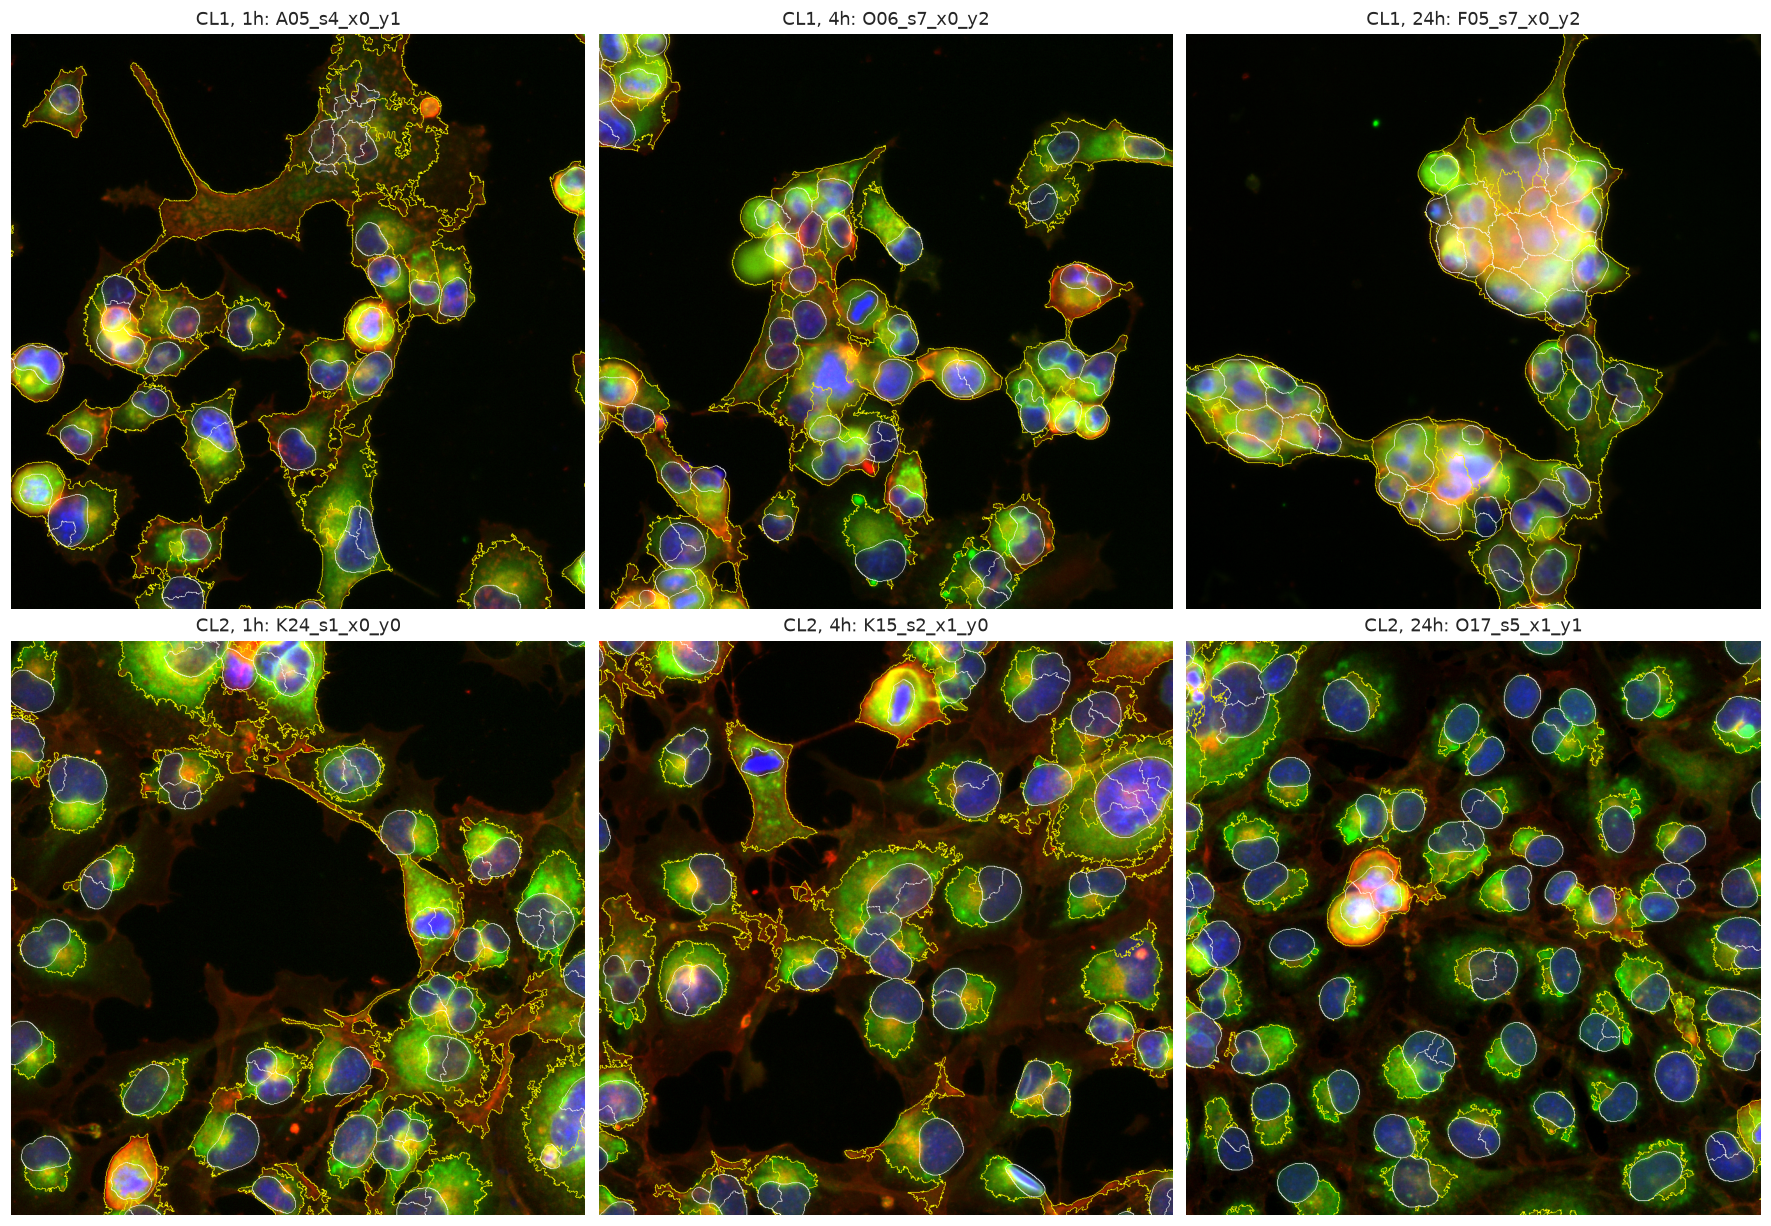

In [15]:
def plate_paths(time):
    """Folders with the masks and illumination functions of one plate."""
    plate = plate_names[time]
    run_dir = pathlib.Path((results_dir / plate / "DONE").read_text().strip())
    return run_dir / "masks" / plate, run_dir / "illum" / plate


def read_image(time, site, channel):
    """Read one raw image, scaled from 0 to 1."""
    path = images_dir / plate_names[time] / f"{site}_Fluorescence_{channel_wavelength[channel]}_nm_Ex.tiff"
    return np.array(Image.open(path), dtype=float) / 65535


def read_mask(time, site, name):
    """Read one label image: 0 is background, each object has its own number."""
    return np.array(Image.open(plate_paths(time)[0] / f"{site}_{name}.tiff")).astype(np.int32)


def outlines(labels):
    """Pixels where one object meets another object or the background."""
    edge = np.zeros(labels.shape, bool)
    edge[:-1, :] |= labels[:-1, :] != labels[1:, :]
    edge[:, :-1] |= labels[:, :-1] != labels[:, 1:]
    return edge


def composite(time, site, crop=900):
    """Color image of the middle of one site, with outlines drawn on it."""
    start = (image_size - crop) // 2
    window = (slice(start, start + crop), slice(start, start + crop))

    def stretch(image):
        low, high = np.percentile(image[window], [1, 99.7])
        return np.clip((image[window] - low) / (high - low), 0, 1)

    rgb = np.dstack([stretch(read_image(time, site, ch)) for ch in ("AGP", "ER", "DNA")])
    rgb[outlines(read_mask(time, site, "CellsPaired")[window])] = (1, 1, 0)
    rgb[outlines(read_mask(time, site, "NucleiPaired")[window])] = (1, 1, 1)
    return rgb


def typical_site(time, line):
    """The control site with the cell count closest to the median of its group."""
    group = images.filter((pl.col("plate") == time) & (pl.col("cell_line") == line) & (pl.col("well_type") == "control"))
    target = group["Image_Count_Cells"].median()
    return group.sort((pl.col("Image_Count_Cells") - target).abs()).item(0, "Metadata_Acquisition")


fig, axes = plt.subplots(2, 3, figsize=(16, 11), constrained_layout=True)
for i, line in enumerate(["CL1", "CL2"]):
    for j, time in enumerate(plate_order):
        site = typical_site(time, line)
        axes[i, j].imshow(composite(time, site))
        axes[i, j].set_title(f"{line}, {time}: {site}")
        axes[i, j].axis("off")
plt.show()

**What we found**

**Two problems are clear.**

1. **White lines cut through single nuclei.** This is common in CL2, and it also happens in CL1. A real nucleus should have one smooth outline.
2. **Yellow cell outlines are ragged and too small.** In CL2, the outlines follow the bright green core of the cell and miss the wide, dim red area around it. This dim area looks like real cytoplasm, but someone who knows these cells should confirm this.

CL1 cells are smaller and grow in tight groups. CL2 cells are large and flat. One group of settings must work for both.

### 7.2 Do nuclei fit the allowed size range?

**What we check:** the size of all nuclei, compared with the 20 to 80 pixel range set in the pipeline.

**Why it matters:** CellProfiler throws away any object outside this range. If real nuclei are bigger than 80 pixels, they get lost, or only their smaller pieces survive.

**What good looks like:** the sizes fall smoothly to near zero before the limits. A sharp cliff at a limit means the limit is cutting real nuclei. At most 0.5% of nuclei should be within 5% of the upper limit.

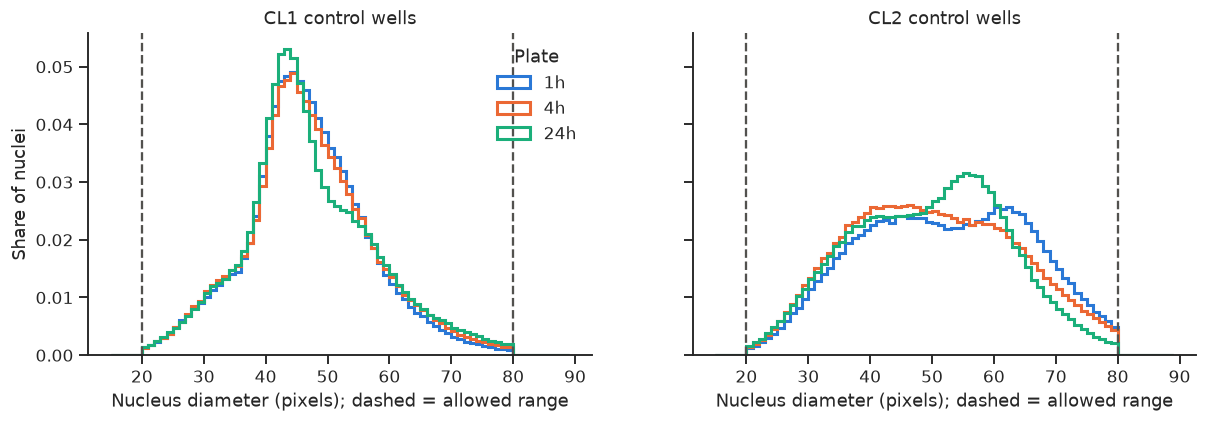

shape: (6, 4)
┌───────────┬───────┬──────────────────────┬─────────────────┐
│ cell_line ┆ plate ┆ pct_near_upper_limit ┆ median_diameter │
│ ---       ┆ ---   ┆ ---                  ┆ ---             │
│ str       ┆ str   ┆ f64                  ┆ f64             │
╞═══════════╪═══════╪══════════════════════╪═════════════════╡
│ CL1       ┆ 1h    ┆ 0.46                 ┆ 46.3            │
│ CL1       ┆ 24h   ┆ 0.9                  ┆ 45.7            │
│ CL1       ┆ 4h    ┆ 0.65                 ┆ 46.4            │
│ CL2       ┆ 1h    ┆ 2.47                 ┆ 52.0            │
│ CL2       ┆ 24h   ┆ 1.14                 ┆ 50.2            │
│ CL2       ┆ 4h    ┆ 2.16                 ┆ 49.6            │
└───────────┴───────┴──────────────────────┴─────────────────┘


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, line in zip(axes, ["CL1", "CL2"]):
    for time in plate_order:
        values = cells.filter((pl.col("plate") == time) & (pl.col("cell_line") == line) & (pl.col("well_type") == "control"))
        ax.hist(
            values["Nuclei_AreaShape_EquivalentDiameter"].to_numpy(), bins=np.arange(15, 90, 1),
            density=True, histtype="step", lw=2, color=plate_colors[time], label=time,
        )
    for limit in nucleus_diameter_range:
        ax.axvline(limit, color="#52514e", ls="--")
    ax.set(title=f"{line} control wells", xlabel="Nucleus diameter (pixels); dashed = allowed range")
axes[0].set_ylabel("Share of nuclei")
axes[0].legend(title="Plate", frameon=False)
plt.show()

near_limit = (
    cells.group_by("cell_line", "plate")
    .agg(
        (100 * (pl.col("Nuclei_AreaShape_EquivalentDiameter") > 0.95 * nucleus_diameter_range[1]).mean()).round(2).alias("pct_near_upper_limit"),
        pl.col("Nuclei_AreaShape_EquivalentDiameter").median().round(1).alias("median_diameter"),
    )
    .sort("cell_line", "plate")
)
print(near_limit)
for row in near_limit.iter_rows(named=True):
    score("Nuclei near the upper size limit (%)", row["pct_near_upper_limit"], f"{row['plate']} {row['cell_line']}")

**What we found**

**Fail, mainly in CL2.** Up to 2.47% of CL2 nuclei sit near the 80 pixel limit, and the CL2 curve stops abruptly at the limit, so the limit cuts off real nuclei. CL1 has fewer nuclei at the limit (0.46 to 0.90%).

The odd, flat shape of the CL2 curve is a second warning. It looks like a mix of whole nuclei and pieces.

### 7.3 Does each nucleus hold a full set of DNA?

**What we check:** the total DNA signal in each nucleus.

**Why it matters:** this check is a built-in positive control, and it needs no labels. A healthy cell has one full set of DNA before it copies its DNA (G1 phase) and two sets after (G2 phase). So the total DNA should show two peaks, with the second at twice the first. A piece of a cut nucleus holds only part of the DNA, so it falls below the first peak.

**What good looks like:** two peaks about a factor of 2 apart, and fewer than 10% of nuclei below 70% of the first peak. Dying cells and debris also fall below the peak, so a small share is normal.

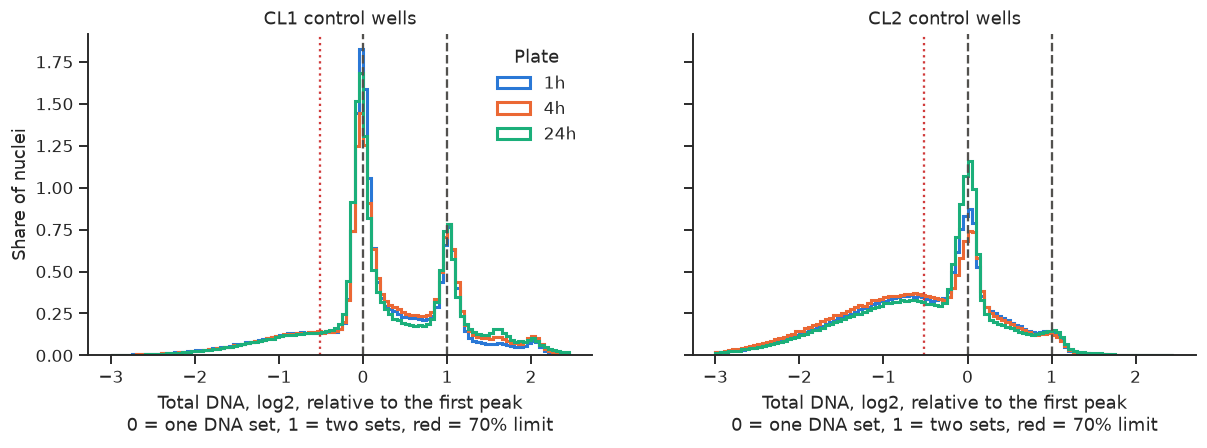

shape: (6, 4)
┌───────────┬───────┬───────────┬────────────────────┐
│ cell_line ┆ plate ┆ peak_log2 ┆ pct_too_little_dna │
│ ---       ┆ ---   ┆ ---       ┆ ---                │
│ str       ┆ str   ┆ f64       ┆ f64                │
╞═══════════╪═══════╪═══════════╪════════════════════╡
│ CL1       ┆ 1h    ┆ 8.18      ┆ 14.4               │
│ CL1       ┆ 4h    ┆ 8.18      ┆ 13.9               │
│ CL1       ┆ 24h   ┆ 8.18      ┆ 13.7               │
│ CL2       ┆ 1h    ┆ 8.88      ┆ 45.6               │
│ CL2       ┆ 4h    ┆ 8.82      ┆ 49.6               │
│ CL2       ┆ 24h   ┆ 8.82      ┆ 42.3               │
└───────────┴───────┴───────────┴────────────────────┘


In [17]:
def g1_peak(values):
    """Position of the tallest peak of the DNA signal, on a log2 scale."""
    counts, bin_edges = np.histogram(values, bins=120, range=(5, 12))
    smooth = ndi.gaussian_filter1d(counts.astype(float), 1.5)
    return bin_edges[np.argmax(smooth)] + (bin_edges[1] - bin_edges[0]) / 2


fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
low_dna = []
for ax, line in zip(axes, ["CL1", "CL2"]):
    for time in plate_order:
        values = np.log2(
            cells.filter((pl.col("plate") == time) & (pl.col("cell_line") == line) & (pl.col("well_type") == "control"))
            ["Nuclei_Intensity_IntegratedIntensity_CorrDNA"].to_numpy()
        )
        peak = g1_peak(values)
        share = 100 * np.mean(values < peak + np.log2(0.7))
        low_dna.append({"cell_line": line, "plate": time, "peak_log2": round(peak, 2), "pct_too_little_dna": round(share, 1)})
        ax.hist(values - peak, bins=np.arange(-3, 2.5, 0.05), density=True, histtype="step", lw=2, color=plate_colors[time], label=time)
    ax.axvline(0, color="#52514e", ls="--")
    ax.axvline(1, color="#52514e", ls="--")
    ax.axvline(np.log2(0.7), color="#d03b3b", ls=":")
    ax.set(title=f"{line} control wells", xlabel="Total DNA, log2, relative to the first peak\n0 = one DNA set, 1 = two sets, red = 70% limit")
axes[0].set_ylabel("Share of nuclei")
axes[0].legend(title="Plate", frameon=False)
plt.show()

low_dna = pl.DataFrame(low_dna)
print(low_dna)
for row in low_dna.iter_rows(named=True):
    score("Nuclei with too little DNA (%)", row["pct_too_little_dna"], f"{row['plate']} {row['cell_line']}")

**What we found**

**Fail, and this check gives the clearest result.**

- CL1 shows two sharp peaks a factor of 2 apart, as expected. So the DNA stain and the intensity measurement work well.
- CL2 has a sharp first peak, but a large, wide shoulder lies below it, and the second peak is weak.
- 42 to 50% of CL2 objects and 14% of CL1 objects hold too little DNA to be a whole nucleus. Some of these may be dying cells, but this does not explain half of the objects in a control well.

### 7.4 Are nuclei being cut, or lost?

**What we check:** we go back to the images and the saved masks to answer two questions.

1. **Cut nuclei.** Do objects touch and form one smooth, round shape? Two separate nuclei that touch usually form a shape with a dent. One nucleus cut in two forms a smooth shape. We call a group "one cut nucleus" when its solidity (how close it is to a filled, convex shape) is at least 0.9.
2. **Lost nuclei.** Is there bright DNA signal with no nucleus object on it? This is what remains when CellProfiler throws an object away.

**Why it matters:** this test shows *why* the DNA check above did or did not pass. It also gives us the real nucleus size, so we can choose a better setting.

**What good looks like:**

- Fewer than 2% of objects are pieces of one cut nucleus.
- Fewer than 2% of DNA signal pixels have no nucleus object.
- Positive control: if cutting is the real cause, joining the pieces back together must move the low-DNA objects up to the first peak. If the share of low-DNA objects stays the same, the cause is something else.

In [18]:
def measure_site(time, site, threshold, illumination):
    """Measure cut and lost nuclei and the signal captured by cell outlines in one site."""
    labels = read_mask(time, site, "NucleiPaired")
    cell_labels = read_mask(time, site, "CellsPaired")
    dna = read_image(time, site, "DNA") / illumination
    agp = read_image(time, site, "AGP")

    # join all touching objects into groups
    groups, n_groups = ndi.label(labels > 0, structure=np.ones((3, 3)))
    group_ids = np.arange(1, n_groups + 1)
    group_area = ndi.sum_labels(np.ones(labels.shape), groups, group_ids)
    group_dna = ndi.sum_labels(dna, groups, group_ids)
    pairs = np.unique(np.column_stack([labels[labels > 0], groups[labels > 0]]), axis=0)
    n_objects = np.bincount(pairs[:, 1], minlength=n_groups + 1)[1:]

    solidity = np.ones(n_groups)
    for index, box in enumerate(ndi.find_objects(groups)):
        if n_objects[index] > 1:
            y, x = np.nonzero(groups[box] == index + 1)
            solidity[index] = group_area[index] / ConvexHull(np.column_stack([y, x])).volume

    object_ids = np.arange(1, labels.max() + 1)
    object_area = ndi.sum_labels(np.ones(labels.shape), labels, object_ids)
    object_dna = ndi.sum_labels(dna, labels, object_ids)
    object_group = ndi.maximum(groups, labels, object_ids).astype(int)

    # DNA signal that no object covers, found with the threshold CellProfiler used for this site
    foreground = ndi.gaussian_filter(dna, 1.3488) > threshold
    unclaimed, n_unclaimed = ndi.label(foreground)
    has_object = np.zeros(n_unclaimed + 1, bool)
    has_object[np.unique(unclaimed[labels > 0])] = True
    claimed_ids = np.arange(1, n_unclaimed + 1)
    unclaimed_area = ndi.sum_labels(np.ones(labels.shape), unclaimed, claimed_ids)
    lost_area = unclaimed_area[~has_object[1:]]

    # share of the AGP signal above background that lies inside cell outlines
    signal = np.clip(agp - np.percentile(agp, 1), 0, None)

    base = {"plate": time, "site": site}
    summary = {
        **base,
        "objects": len(object_ids),
        "foreground_pixels": int(foreground.sum()),
        "lost_pixels": int(lost_area.sum()),
        "lost_large_objects": int((2 * np.sqrt(lost_area / np.pi) > nucleus_diameter_range[1]).sum()),
        "agp_inside_cells_pct": 100 * signal[cell_labels > 0].sum() / signal.sum(),
    }
    group_table = {
        "group": group_ids, "n_objects": n_objects, "area": group_area, "dna": group_dna, "solidity": solidity,
        "plate": [time] * n_groups, "site": [site] * n_groups,
    }
    object_table = {
        "area": object_area, "dna": object_dna, "group": object_group,
        "plate": [time] * len(object_ids), "site": [site] * len(object_ids),
    }
    return summary, group_table, object_table


def measure_group(args):
    """Measure one site, for use in a thread pool."""
    return measure_site(*args)


group_path = cache_dir / "nuclei_groups.parquet"
object_path = cache_dir / "nuclei_objects.parquet"
summary_path = cache_dir / "site_segmentation.parquet"

if not (group_path.exists() and object_path.exists() and summary_path.exists()):
    chosen = (
        images.filter(pl.col("well_type") == "control")
        .filter(pl.int_range(pl.len()).shuffle(seed=seed).over("plate", "cell_line") < images_per_group)
        .select("plate", "Metadata_Acquisition", "Image_Threshold_FinalThreshold_NucleiPaired")
    )
    jobs = []
    for time, site, threshold in chosen.iter_rows():
        jobs.append((time, site, threshold, np.load(plate_paths(time)[1] / "IllumDNA.npy")))
    with ThreadPoolExecutor(n_threads) as pool:
        results = list(pool.map(measure_group, jobs))
    pl.DataFrame([r[0] for r in results]).write_parquet(summary_path)
    pl.concat([pl.DataFrame(r[1]) for r in results]).write_parquet(group_path)
    pl.concat([pl.DataFrame(r[2]) for r in results]).write_parquet(object_path)

site_lookup = images.select(pl.col("Metadata_Acquisition").alias("site"), "plate", "cell_line", pl.col("Metadata_Well"))
site_segmentation = pl.read_parquet(summary_path).join(site_lookup, on=["site", "plate"])
nuclei_groups = pl.read_parquet(group_path).join(site_lookup, on=["site", "plate"])
nuclei_objects = pl.read_parquet(object_path).join(site_lookup, on=["site", "plate"])
print(site_segmentation.height, "sites,", nuclei_objects.height, "objects")

72 sites, 33617 objects


In [19]:
cut_table = (
    nuclei_groups.group_by("cell_line", "plate")
    .agg(
        pl.col("n_objects").sum().alias("objects"),
        pl.col("n_objects").filter((pl.col("n_objects") > 1) & (pl.col("solidity") >= 0.9)).sum().alias("objects_in_cut_nuclei"),
        (2 * (pl.col("area").filter((pl.col("n_objects") > 1) & (pl.col("solidity") >= 0.9)) / np.pi).sqrt()).median().round(1).alias("median_cut_nucleus_diameter"),
    )
    .with_columns((100 * pl.col("objects_in_cut_nuclei") / pl.col("objects")).round(1).alias("pct_cut"))
    .join(
        site_segmentation.group_by("cell_line", "plate").agg(
            (100 * pl.col("lost_pixels").sum() / pl.col("foreground_pixels").sum()).round(1).alias("pct_lost_signal"),
            pl.col("lost_large_objects").sum().alias("lost_objects_over_80px"),
            pl.col("agp_inside_cells_pct").median().round(1).alias("agp_inside_cells_pct"),
        ),
        on=["cell_line", "plate"],
    )
    .sort("cell_line", "plate")
)
print(cut_table)

for row in cut_table.iter_rows(named=True):
    group = f"{row['plate']} {row['cell_line']}"
    score("Objects that are pieces of a cut nucleus (%)", row["pct_cut"], group)
    score("DNA signal without a nucleus object (%)", row["pct_lost_signal"], group)

shape: (6, 9)
┌───────────┬───────┬─────────┬───────────────────────┬─────────────────────────────┬─────────┬─────────────────┬────────────────────────┬──────────────────────┐
│ cell_line ┆ plate ┆ objects ┆ objects_in_cut_nuclei ┆ median_cut_nucleus_diameter ┆ pct_cut ┆ pct_lost_signal ┆ lost_objects_over_80px ┆ agp_inside_cells_pct │
│ ---       ┆ ---   ┆ ---     ┆ ---                   ┆ ---                         ┆ ---     ┆ ---             ┆ ---                    ┆ ---                  │
│ str       ┆ str   ┆ i64     ┆ i64                   ┆ f64                         ┆ f64     ┆ f64             ┆ i64                    ┆ f64                  │
╞═══════════╪═══════╪═════════╪═══════════════════════╪═════════════════════════════╪═════════╪═════════════════╪════════════════════════╪══════════════════════╡
│ CL1       ┆ 1h    ┆ 4302    ┆ 1021                  ┆ 60.7                        ┆ 23.7    ┆ 0.8             ┆ 7                      ┆ 79.0                 │
│ CL1       ┆ 

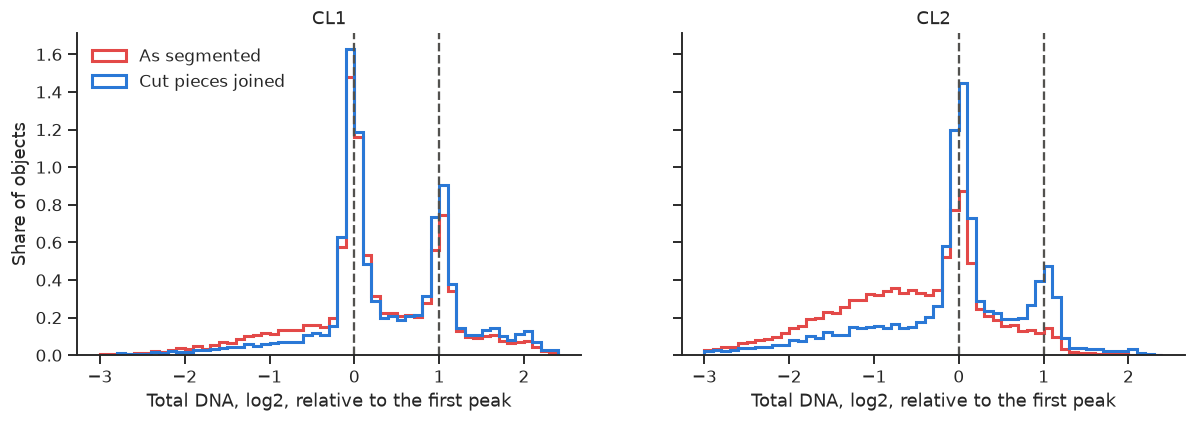

shape: (2, 3)
┌───────────┬──────────────────────────┬───────────────────────────┐
│ cell_line ┆ pct_low_dna_as_segmented ┆ pct_low_dna_after_joining │
│ ---       ┆ ---                      ┆ ---                       │
│ str       ┆ f64                      ┆ f64                       │
╞═══════════╪══════════════════════════╪═══════════════════════════╡
│ CL1       ┆ 15.2                     ┆ 8.6                       │
│ CL2       ┆ 46.6                     ┆ 22.9                      │
└───────────┴──────────────────────────┴───────────────────────────┘
shape: (2, 8)
┌───────────┬──────┬──────┬──────┬──────┬──────┬───────────────┬────────────────┐
│ cell_line ┆ p1   ┆ p5   ┆ p50  ┆ p95  ┆ p99  ┆ pct_over_80px ┆ pct_over_120px │
│ ---       ┆ ---  ┆ ---  ┆ ---  ┆ ---  ┆ ---  ┆ ---           ┆ ---            │
│ str       ┆ f64  ┆ f64  ┆ f64  ┆ f64  ┆ f64  ┆ f64           ┆ f64            │
╞═══════════╪══════╪══════╪══════╪══════╪══════╪═══════════════╪════════════════╡
│ CL1     

In [20]:
# positive control: join the pieces of cut nuclei, then repeat the DNA check
is_cut = (pl.col("n_objects") > 1) & (pl.col("solidity") >= 0.9)
is_touching = (pl.col("n_objects") > 1) & (pl.col("solidity") < 0.9)
repaired = pl.concat(
    [
        # single objects and joined cut nuclei count as one nucleus
        nuclei_groups.filter(~is_touching).select("cell_line", "plate", "dna", "area"),
        # touching nuclei with a dent stay as separate objects
        nuclei_objects.join(nuclei_groups.filter(is_touching), on=["site", "plate", "group"], how="semi")
        .select("cell_line", "plate", "dna", "area"),
    ]
)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
repair_rows = []
for ax, line in zip(axes, ["CL1", "CL2"]):
    before = np.log2(nuclei_objects.filter(pl.col("cell_line") == line)["dna"].to_numpy())
    after = np.log2(repaired.filter(pl.col("cell_line") == line)["dna"].to_numpy())
    peak = g1_peak(after)
    ax.hist(before - peak, bins=np.arange(-3, 2.5, 0.1), density=True, histtype="step", lw=2, color="#e34948", label="As segmented")
    ax.hist(after - peak, bins=np.arange(-3, 2.5, 0.1), density=True, histtype="step", lw=2, color="#2a78d6", label="Cut pieces joined")
    ax.axvline(0, color="#52514e", ls="--")
    ax.axvline(1, color="#52514e", ls="--")
    ax.set(title=line, xlabel="Total DNA, log2, relative to the first peak")
    repair_rows.append(
        {
            "cell_line": line,
            "pct_low_dna_as_segmented": round(100 * np.mean(before < peak + np.log2(0.7)), 1),
            "pct_low_dna_after_joining": round(100 * np.mean(after < peak + np.log2(0.7)), 1),
        }
    )
axes[0].legend(frameon=False)
axes[0].set_ylabel("Share of objects")
plt.show()
print(pl.DataFrame(repair_rows))

# the real nucleus size, after the pieces are joined: this guides the new size range
print(
    repaired.with_columns((2 * (pl.col("area") / np.pi).sqrt()).alias("diameter"))
    .group_by("cell_line")
    .agg(
        *[pl.col("diameter").quantile(q).round(0).alias(f"p{int(100 * q)}") for q in (0.01, 0.05, 0.5, 0.95, 0.99)],
        (100 * (pl.col("diameter") > 80).mean()).round(1).alias("pct_over_80px"),
        (100 * (pl.col("diameter") > 120).mean()).round(1).alias("pct_over_120px"),
    )
    .sort("cell_line")
)

**What we found**

**Fail. Cutting is the main cause, and the positive control supports this.** This test used 72 images from control wells, with 33,617 objects.

- **Cut nuclei:** 18 to 24% of CL1 objects and 41 to 54% of CL2 objects are pieces of a smooth, single shape.
- **Positive control:** when we join the pieces, the low-DNA objects fall from 15.2% to 8.6% in CL1, and from 46.6% to 22.9% in CL2. In CL2, a clear second peak appears at twice the first peak. This is what we expect if the pieces belong together. This result supports H1. We did not expect the share to reach zero, because we only joined smooth shapes, and some low-DNA objects are debris.
- **Lost nuclei:** this is a smaller problem. At most 3.8% of DNA signal has no object, and these lost objects larger than 80 pixels equal about 0.6% of all objects.
- **Real nucleus size:** after joining, the median diameter is 48 pixels in CL1 and 60 pixels in CL2. In CL2, 6.1% of nuclei are over 80 pixels, and only 0.2% are over 120 pixels.

**Why the cutting happens.** The pipeline separates touching nuclei by looking for bright spots inside them. Nuclei have uneven DNA staining, so one nucleus can have several bright spots. The minimum diameter of 20 pixels makes this worse, because CellProfiler uses that value to choose how much to blur the image before it looks for spots. With 20 pixels, it blurs very little, so it finds many spots in the large CL2 nuclei.

### 7.5 Do the cell outlines follow the real cell edges?

**What we check:**

- **Solidity:** how smooth a cell outline is. Ragged outlines have low solidity.
- **Cytoplasm left over:** cytoplasm is the cell minus the nucleus. If a cell outline barely extends past the nucleus, its cytoplasm features describe almost nothing.
- **AGP signal inside cell outlines:** how much of the cell-body staining sits inside an outline. AGP marks the cell membrane and actin, so it shows the full cell area.
- **Stains in the right place:** DNA must be much brighter in the nucleus than in the cytoplasm. This is a positive control for both the outlines and the channel labels.

**Why it matters:** about two thirds of our features come from the Cells and Cytoplasm outlines. Wrong outlines mean that these features measure the wrong pixels.

**What good looks like:** median solidity of at least 0.85, fewer than 2% of cells with cytoplasm below 10% of cell area, at least 90% of AGP signal inside cells, and DNA at least 3 times brighter in the nucleus than in the cytoplasm.

In [21]:
cell_shape = (
    cells.with_columns(
        (pl.col("Cytoplasm_AreaShape_Area").fill_null(0) / pl.col("Cells_AreaShape_Area")).alias("cytoplasm_share")
    )
    .group_by("cell_line", "plate")
    .agg(
        pl.col("Cells_AreaShape_Solidity").median().round(3).alias("median_solidity"),
        pl.col("Cells_AreaShape_Area").median().alias("median_cell_area"),
        pl.col("Nuclei_AreaShape_Area").median().alias("median_nucleus_area"),
        (100 * pl.col("Cytoplasm_AreaShape_Area").is_null().mean()).round(2).alias("pct_no_cytoplasm"),
        (100 * (pl.col("cytoplasm_share") < 0.1).mean()).round(2).alias("pct_almost_no_cytoplasm"),
        (pl.col("Cells_AreaShape_Area") > 100_000).sum().alias("giant_cells"),
    )
    .sort("cell_line", "plate")
)
print(cell_shape)

for row in cell_shape.iter_rows(named=True):
    group = f"{row['plate']} {row['cell_line']}"
    score("Median cell solidity", row["median_solidity"], group)
    score("Cells with almost no cytoplasm (%)", row["pct_almost_no_cytoplasm"], group)
for row in cut_table.iter_rows(named=True):
    score("AGP signal inside cell outlines (%)", row["agp_inside_cells_pct"], f"{row['plate']} {row['cell_line']}")

print(
    images.with_columns((100 * pl.col("Image_Count_Cells") / pl.col("Image_Count_CellsPaired")).alias("kept"))
    .group_by("cell_line", "plate").agg(pl.col("kept").median().round(1).alias("pct_cells_kept_after_border_filter")).sort("cell_line", "plate")
)

shape: (6, 8)
┌───────────┬───────┬─────────────────┬──────────────────┬─────────────────────┬──────────────────┬─────────────────────────┬─────────────┐
│ cell_line ┆ plate ┆ median_solidity ┆ median_cell_area ┆ median_nucleus_area ┆ pct_no_cytoplasm ┆ pct_almost_no_cytoplasm ┆ giant_cells │
│ ---       ┆ ---   ┆ ---             ┆ ---              ┆ ---                 ┆ ---              ┆ ---                     ┆ ---         │
│ str       ┆ str   ┆ f64             ┆ f64              ┆ f64                 ┆ f64              ┆ f64                     ┆ u32         │
╞═══════════╪═══════╪═════════════════╪══════════════════╪═════════════════════╪══════════════════╪═════════════════════════╪═════════════╡
│ CL1       ┆ 1h    ┆ 0.782           ┆ 4219.0           ┆ 1683.0              ┆ 0.25             ┆ 1.67                    ┆ 15          │
│ CL1       ┆ 24h   ┆ 0.801           ┆ 3277.0           ┆ 1643.0              ┆ 1.49             ┆ 6.97                    ┆ 4           │
│ CL1 

In [22]:
compartment_ratio = pl.DataFrame(
    [
        {
            "channel": ch,
            **{
                f"{line} {time}": round(
                    cells.filter((pl.col("cell_line") == line) & (pl.col("plate") == time))
                    .select((pl.col(f"Nuclei_Intensity_MeanIntensity_Corr{ch}") / pl.col(f"Cytoplasm_Intensity_MeanIntensity_Corr{ch}")).median())
                    .item(), 2,
                )
                for line in ("CL1", "CL2") for time in plate_order
            },
        }
        for ch in channels
    ]
)
print("Nucleus brightness divided by cytoplasm brightness (median per cell)")
compartment_ratio

Nucleus brightness divided by cytoplasm brightness (median per cell)


channel,CL1 1h,CL1 4h,CL1 24h,CL2 1h,CL2 4h,CL2 24h
str,f64,f64,f64,f64,f64,f64
"""DNA""",9.49,8.63,8.07,8.87,8.66,8.44
"""RNA""",1.41,1.48,1.57,1.37,1.41,1.58
"""AGP""",1.05,1.05,1.08,0.9,0.85,0.84
"""ER""",1.07,1.09,1.07,0.79,0.78,0.76
"""Mito""",1.23,1.26,1.28,0.96,0.92,0.88


**What we found**

**Fail.**

- **Ragged outlines:** median solidity is 0.78 to 0.80 in every group. The limit is 0.85.
- **Missed cell area:** only 54 to 64% of AGP signal is inside CL2 cells, and 79 to 84% in CL1.
- **Almost no cytoplasm:** 7 to 11% of CL2 cells, and up to 7% of CL1 cells, have cytoplasm below 10% of the cell area. Between 0.25 and 1.82% have no cytoplasm at all. These cells cause the missing values in section 8.
- **Giant objects:** 61 objects are over 100,000 pixels, and the largest covers about a third of an image. They are rare, but they are clearly errors.
- **Stains in the right place:** this positive control passes for DNA, which is 8 to 9.5 times brighter in the nucleus than in the cytoplasm. So the DNA channel is correct. The AGP, ER and Mito ratios are close to 1, which we did not set a limit for. Light from cell parts above and below the nucleus may cause this, but this data cannot show it.

The filter for cells touching the image border removes about 10% of cells on every plate. This is even across plates and is not a concern.

## 8. Are the features usable?

**What we check:** missing values, features that never change, and features that repeat each other.

**Why it matters:** a feature with many missing values or no variation adds no information. Many near-identical features give one kind of measurement too much weight.

**What good looks like:** few missing values and few constant features. Many similar features are normal in CellProfiler data, and we remove them later.

In [23]:
null_counts = pl.concat(
    [pl.read_csv(path) for path in sorted(profiles_dir.glob("*.null_counts.csv"))]
).group_by("column").agg(pl.col("n_null").sum())
n_cells = cells.height
feature_nulls = null_counts.filter(pl.col("column").is_in(features)).with_columns((100 * pl.col("n_null") / n_cells).alias("pct_missing"))

spread = cell_sample.select(pl.col(features).std()).transpose(include_header=True, column_names=["std"])
constant = spread.filter((pl.col("std") == 0) | pl.col("std").is_null())["column"].to_list()

print(f"Features: {len(features)}")
print(f"Features with no missing values: {feature_nulls.filter(pl.col('n_null') == 0).height}")
print(f"Features with over 1% missing: {feature_nulls.filter(pl.col('pct_missing') > 1).height}")
print(f"Features with over 5% missing: {feature_nulls.filter(pl.col('pct_missing') > 5).height}")
print(f"Largest share missing: {feature_nulls['pct_missing'].max():.2f}%")
print(f"Constant features: {len(constant)}", constant[:6])
print(feature_nulls.sort("n_null", descending=True).head(5))

Features: 3041
Features with no missing values: 1990
Features with over 1% missing: 914
Features with over 5% missing: 0
Largest share missing: 1.46%
Constant features: 0 []
shape: (5, 3)
┌───────────────────────────────────────────────────┬────────┬─────────────┐
│ column                                            ┆ n_null ┆ pct_missing │
│ ---                                               ┆ ---    ┆ ---         │
│ str                                               ┆ i64    ┆ f64         │
╞═══════════════════════════════════════════════════╪════════╪═════════════╡
│ Cytoplasm_AreaShape_FormFactor                    ┆ 64018  ┆ 1.462318    │
│ Cytoplasm_Correlation_Correlation_CorrDNA_CorrRNA ┆ 54741  ┆ 1.25041     │
│ Cytoplasm_Correlation_Correlation_CorrRNA_CorrER  ┆ 54738  ┆ 1.250342    │
│ Cytoplasm_Correlation_Correlation_CorrDNA_CorrER  ┆ 54732  ┆ 1.250205    │
│ Cytoplasm_Correlation_Correlation_CorrRNA_CorrAGP ┆ 54731  ┆ 1.250182    │
└─────────────────────────────────────────

In [24]:
well_columns = ["plate", "Metadata_Well", "cell_line", "well_type", "treatment", "edge", "row", "column"]
usable = [f for f in features if f not in set(constant)]

well_profiles = site_profiles.group_by(well_columns).agg(
    pl.col("n_cells").sum(), pl.col(usable).median()
).sort("plate", "Metadata_Well")
normalized = []
for (time, line), group in well_profiles.group_by("plate", "cell_line", maintain_order=True):
    control = group.filter(pl.col("well_type") == "control").select(usable).to_numpy()
    center = np.nanmedian(control, axis=0)
    mad = np.nanmedian(np.abs(control - center), axis=0) * 1.4826
    mad[mad == 0] = np.nan
    values = (group.select(usable).to_numpy() - center) / mad
    normalized.append((group.drop(usable), values))

well_info = pl.concat([info for info, _ in normalized])
well_matrix = np.nan_to_num(np.vstack([values for _, values in normalized]), nan=0, posinf=0, neginf=0).clip(-20, 20)

# keep features that differ between wells, and drop near copies of a kept feature
order = np.argsort(-np.median(np.abs(well_matrix), axis=0))
order = order[well_matrix[:, order].std(axis=0) > 0]
correlation = np.corrcoef(well_matrix[:, order], rowvar=False)
kept = []
for index in range(len(order)):
    if not kept or np.abs(correlation[index, kept]).max() < 0.9:
        kept.append(index)
selected = order[kept]
selected_names = [usable[i] for i in selected]
print(f"{len(usable)} usable features -> {len(selected)} after dropping near copies (|r| >= 0.9)")
print(pl.Series([name.split("_")[0] + "_" + name.split("_")[1] for name in selected_names]).value_counts(sort=True).head(12))

3041 usable features -> 840 after dropping near copies (|r| >= 0.9)
shape: (12, 2)
┌──────────────────────────────┬───────┐
│                              ┆ count │
│ ---                          ┆ ---   │
│ str                          ┆ u32   │
╞══════════════════════════════╪═══════╡
│ Nuclei_RadialDistribution    ┆ 80    │
│ Cells_RadialDistribution     ┆ 75    │
│ Cytoplasm_Texture            ┆ 75    │
│ Cytoplasm_RadialDistribution ┆ 63    │
│ Cytoplasm_Granularity        ┆ 58    │
│ Nuclei_Granularity           ┆ 56    │
│ Cytoplasm_Correlation        ┆ 48    │
│ Cells_Texture                ┆ 44    │
│ Nuclei_Texture               ┆ 43    │
│ Nuclei_Correlation           ┆ 41    │
│ Cells_Correlation            ┆ 41    │
│ Nuclei_AreaShape             ┆ 40    │
└──────────────────────────────┴───────┘


**What we found**

**Pass.** No feature is constant, and the largest share of missing values is 1.46%. All 3,041 features can stay, and 840 remain after we remove near copies. Removing near copies is a normal step.

This pass has a limit: these checks only show that the numbers exist. They cannot show that the numbers describe the right objects. Section 7 shows that many do not.

## 9. Do the profiles carry biology or noise?

The earlier checks ask whether the measurements look right. This section asks whether they are useful. Good profiles should meet three conditions:

1. Differences in control wells come from cell line and time, not from the plate position.
2. Replicate wells of a treatment look more alike than wells of different treatments.
3. A treatment with a known effect shows that effect.

### 9.1 What drives the differences between control wells?

**What we check:** how much of the variation in control wells links to plate, cell line and cell count.

**Why it matters:** cell line and plate are expected to matter. But the 24h plate used longer exposures, so time and exposure cannot be separated. Cell count effects can also hide treatment effects.

**What good looks like:** plate and cell line form clear groups. Inside each group, cell count explains only a small part of the variation.

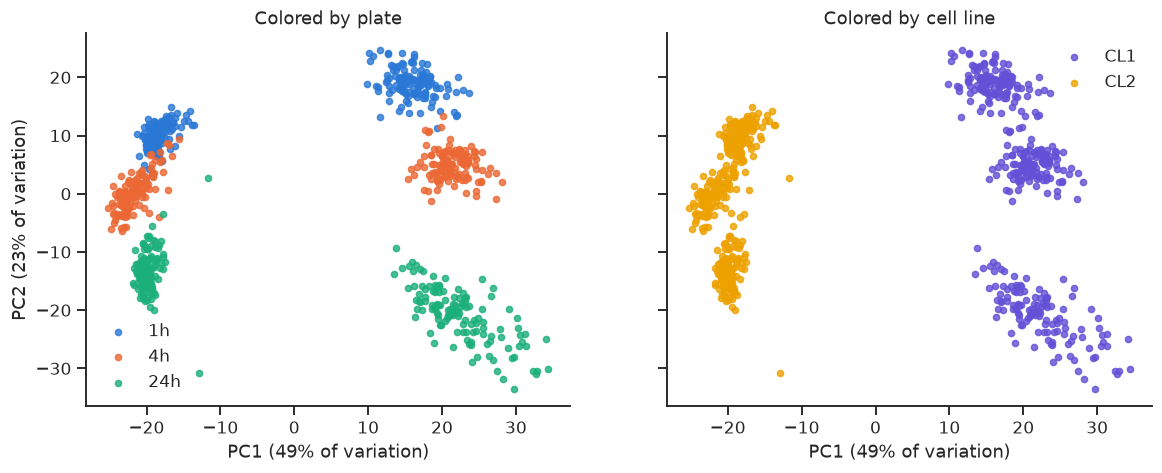

Median share of feature variation in control wells:
  plate:     0.15
  cell line: 0.50


In [25]:
control_raw = well_profiles.filter(pl.col("well_type") == "control")
raw_matrix = control_raw.select(selected_names).to_numpy()
raw_matrix = np.nan_to_num((raw_matrix - np.nanmedian(raw_matrix, axis=0)) / (np.nanstd(raw_matrix, axis=0) + 1e-9), nan=0, posinf=0, neginf=0).clip(-10, 10)
pca = PCA(n_components=2, random_state=seed)
scores = pca.fit_transform(raw_matrix)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), sharex=True, sharey=True)
for time in plate_order:
    mask = (control_raw["plate"] == time).to_numpy()
    axes[0].scatter(*scores[mask].T, s=16, color=plate_colors[time], label=time, alpha=0.8)
for line in ["CL1", "CL2"]:
    mask = (control_raw["cell_line"] == line).to_numpy()
    axes[1].scatter(*scores[mask].T, s=16, color=line_colors[line], label=line, alpha=0.8)
for ax, title in zip(axes, ["Colored by plate", "Colored by cell line"]):
    ax.set(title=title, xlabel=f"PC1 ({100 * pca.explained_variance_ratio_[0]:.0f}% of variation)")
    ax.legend(frameon=False)
axes[0].set_ylabel(f"PC2 ({100 * pca.explained_variance_ratio_[1]:.0f}% of variation)")
plt.show()


def share_explained(matrix, groups):
    """Share of each feature's variation that lies between groups."""
    labels = np.unique(groups, return_inverse=True)[1]
    total = ((matrix - matrix.mean(axis=0)) ** 2).sum(axis=0)
    between = np.zeros(matrix.shape[1])
    for label in np.unique(labels):
        part = matrix[labels == label]
        between += len(part) * (part.mean(axis=0) - matrix.mean(axis=0)) ** 2
    return between / np.where(total == 0, np.nan, total)


plate_labels = control_raw["plate"].to_numpy()
line_labels = control_raw["cell_line"].to_numpy()
print("Median share of feature variation in control wells:")
print(f"  plate:     {np.nanmedian(share_explained(raw_matrix, plate_labels)):.2f}")
print(f"  cell line: {np.nanmedian(share_explained(raw_matrix, line_labels)):.2f}")

In [26]:
# inside each plate and cell line: how strongly does cell count drive the profile?
rows = []
for (time, line), part in well_info.with_row_index("position").filter(pl.col("well_type") == "control").group_by("plate", "cell_line"):
    position = part["position"].to_numpy()
    matrix = well_matrix[position][:, selected]
    counts = np.log2(part["n_cells"].to_numpy().astype(float))
    counts = (counts - counts.mean()) / counts.std()
    z = (matrix - matrix.mean(axis=0)) / (matrix.std(axis=0) + 1e-9)
    r = (z * counts[:, None]).mean(axis=0)
    rows.append({"cell_line": line, "plate": time, "median_r2_with_cell_count": round(float(np.nanmedian(r ** 2)), 3), "pct_features_r2_over_0.25": round(100 * float(np.mean(r ** 2 > 0.25)), 1)})
print(pl.DataFrame(rows).sort("cell_line", "plate"))

shape: (6, 4)
┌───────────┬───────┬───────────────────────────┬───────────────────────────┐
│ cell_line ┆ plate ┆ median_r2_with_cell_count ┆ pct_features_r2_over_0.25 │
│ ---       ┆ ---   ┆ ---                       ┆ ---                       │
│ str       ┆ str   ┆ f64                       ┆ f64                       │
╞═══════════╪═══════╪═══════════════════════════╪═══════════════════════════╡
│ CL1       ┆ 1h    ┆ 0.055                     ┆ 17.1                      │
│ CL1       ┆ 24h   ┆ 0.312                     ┆ 55.7                      │
│ CL1       ┆ 4h    ┆ 0.053                     ┆ 20.1                      │
│ CL2       ┆ 1h    ┆ 0.069                     ┆ 18.9                      │
│ CL2       ┆ 24h   ┆ 0.134                     ┆ 37.4                      │
│ CL2       ┆ 4h    ┆ 0.242                     ┆ 49.5                      │
└───────────┴───────┴───────────────────────────┴───────────────────────────┘


**What we found**

**As expected for plate and cell line, with a warning for cell count.**

- Control wells form 6 clear groups, one per plate and cell line. Cell line explains the most (median share 0.50), and plate less (0.15). Two wells on the 24h plate sit outside their group.
- The plate effect mixes time and exposure, as section 1 explains.
- **Cell count has a strong effect in some groups.** It explains over 25% of the variation in 56% of features for CL1 at 24h, and in 50% for CL2 at 4h. In the other groups the share is 17 to 37%. So density is a real source of noise, and the later analysis must account for it.

### 9.2 Do replicate wells agree?

**What we check:** the share of treatments whose 3 replicate wells look more alike than random wells of different treatments. This share is called **percent replicating**. We test each plate and cell line on its own.

**Why it matters:** this is the most useful summary of profile quality. If replicates do not agree, a treatment's profile is mostly noise.

**What good looks like:** at least 50% of treatments replicate.

**Negative control:** random groups of 3 DMSO wells have no shared treatment, so only about 5% should pass. If many pass, the test is biased, and position or plate effects are the likely cause.

We use a pass line of the 95th percentile of the random groups.

In [27]:
rng = np.random.default_rng(seed)
n_null = 2000


def median_pairwise_correlation(matrix):
    """Median correlation between all pairs of rows."""
    values = np.corrcoef(matrix)
    return np.nanmedian(values[np.triu_indices(len(matrix), 1)])


def replicate_test(info, matrix):
    """Compare replicate agreement with random groups, for one plate and cell line."""
    treated = info.filter(pl.col("well_type") != "control")
    treatments = treated["treatment"].to_numpy()
    treated_positions = treated["position"].to_numpy()
    control_positions = info.filter(pl.col("well_type") == "control")["position"].to_numpy()

    null = []
    while len(null) < n_null:
        pick = rng.choice(len(treated_positions), 3, replace=False)
        if len(set(treatments[pick])) == 3:
            null.append(median_pairwise_correlation(matrix[treated_positions[pick]]))
    null = np.array(null)
    line = np.nanquantile(null, 0.95)

    rows = []
    for treatment in np.unique(treatments):
        members = treated_positions[treatments == treatment]
        if len(members) < 2:
            continue
        value = median_pairwise_correlation(matrix[members])
        rows.append({"treatment": treatment, "correlation": value, "null_line": line, "p": (1 + np.sum(null >= value)) / (1 + len(null))})

    control_values = np.array([
        median_pairwise_correlation(matrix[rng.choice(control_positions, 3, replace=False)]) for _ in range(500)
    ])
    return rows, float(np.nanmean(control_values >= line) * 100)


replicate_rows = []
control_pass = []
indexed = well_info.with_row_index("position")
selected_matrix = well_matrix[:, selected]
for time in plate_order:
    for line in ["CL1", "CL2"]:
        part = indexed.filter((pl.col("plate") == time) & (pl.col("cell_line") == line))
        rows, control_rate = replicate_test(part, selected_matrix)
        replicate_rows += [{"plate": time, "cell_line": line, **row} for row in rows]
        control_pass.append({"plate": time, "cell_line": line, "dmso_pass_pct": round(control_rate, 1)})

replicates = pl.DataFrame(replicate_rows).with_columns(
    pl.col("treatment").str.contains("TGFb1|IL6").alias("is_ligand")
)
replicates = replicates.with_columns(
    pl.Series("fdr", multipletests(replicates["p"].to_numpy(), method="fdr_bh")[1]),
)
replicating = (
    replicates.group_by("plate", "cell_line")
    .agg(
        pl.len().alias("treatments"),
        (pl.col("correlation") > pl.col("null_line")).sum().alias("replicating"),
        (pl.col("fdr") < 0.05).sum().alias("replicating_fdr_0.05"),
        pl.col("correlation").median().round(2).alias("median_correlation"),
        pl.col("null_line").first().round(2),
    )
    .with_columns((100 * pl.col("replicating") / pl.col("treatments")).round(1).alias("pct_replicating"))
    .join(pl.DataFrame(control_pass), on=["plate", "cell_line"])
)
low, high = proportion_confint(replicating["replicating"].to_numpy(), replicating["treatments"].to_numpy(), method="wilson")
replicating = replicating.with_columns(
    pl.Series("ci_low", (100 * low).round(0)), pl.Series("ci_high", (100 * high).round(0))
).sort("cell_line", "plate")
print(replicating)

for row in replicating.iter_rows(named=True):
    group = f"{row['plate']} {row['cell_line']}"
    score("Replicating treatments (%)", row["pct_replicating"], group)
    score("Replicating DMSO groups (negative control, %)", row["dmso_pass_pct"], group)

shape: (6, 11)
┌───────┬───────────┬────────────┬─────────────┬──────────────────────┬────────────────────┬───────────┬─────────────────┬───────────────┬────────┬─────────┐
│ plate ┆ cell_line ┆ treatments ┆ replicating ┆ replicating_fdr_0.05 ┆ median_correlation ┆ null_line ┆ pct_replicating ┆ dmso_pass_pct ┆ ci_low ┆ ci_high │
│ ---   ┆ ---       ┆ ---        ┆ ---         ┆ ---                  ┆ ---                ┆ ---       ┆ ---             ┆ ---           ┆ ---    ┆ ---     │
│ str   ┆ str       ┆ u32        ┆ u32         ┆ u32                  ┆ f64                ┆ f64       ┆ f64             ┆ f64           ┆ f64    ┆ f64     │
╞═══════╪═══════════╪════════════╪═════════════╪══════════════════════╪════════════════════╪═══════════╪═════════════════╪═══════════════╪════════╪═════════╡
│ 1h    ┆ CL1       ┆ 21         ┆ 4           ┆ 4                    ┆ 0.05               ┆ 0.34      ┆ 19.0            ┆ 4.4           ┆ 8.0    ┆ 40.0    │
│ 24h   ┆ CL1       ┆ 21         ┆ 9 

**What we found**

**Mixed, but this is the most encouraging result.**

- Percent replicating is 19 to 24% at 1h, 48% at 4h, and 43 to 62% at 24h. Only CL2 at 24h meets the 50% limit. Each value rests on 21 treatments, so the ranges are wide (for example, 41 to 79% for CL2 at 24h).
- It rises with time, which is what we expect, because treatments need time to change cells. Many treatments may also have no effect, so 100% is not a realistic target.
- **The negative control passes:** 1.4 to 7.2% of random DMSO groups pass, close to the expected 5%. So the test is not biased.

These profiles carry real signal even with the segmentation errors. We expect cleaner outlines to improve this result, but we have not tested that.

### 9.3 Does a known treatment show the expected effect?

**What we check:** how far each treatment moves from DMSO, by dose and time. We use TGFβ1 as the positive control, because TGFβ1 is known to change cell shape and adhesion (epithelial-mesenchymal transition) in many pancreatic cancer lines. We expect the effect to grow with time and dose. CL1 and CL2 may respond differently, and we cannot predict this from the metadata.

**Why it matters:** replicate agreement shows that a signal is reproducible. It does not show that the signal is biology. A known effect supports that.

**What good looks like:** TGFβ1 moves further from DMSO at 24h than at 1h, and further at the high dose than at the low dose.

We measure the distance as the median absolute feature change compared with the plate's DMSO wells. A control well gives about 0.6 to 0.7, so that is the level of noise.

shape: (14, 5)
┌───────────┬───────────┬──────┬──────┬──────┐
│ cell_line ┆ treatment ┆ 1h   ┆ 4h   ┆ 24h  │
│ ---       ┆ ---       ┆ ---  ┆ ---  ┆ ---  │
│ str       ┆ str       ┆ f64  ┆ f64  ┆ f64  │
╞═══════════╪═══════════╪══════╪══════╪══════╡
│ CL1       ┆ DMSO      ┆ 0.67 ┆ 0.64 ┆ 0.64 │
│ CL1       ┆ IL6_H     ┆ 0.6  ┆ 0.64 ┆ 1.05 │
│ CL1       ┆ IL6_L     ┆ 0.75 ┆ 0.62 ┆ 0.93 │
│ CL1       ┆ IL6_M     ┆ 0.67 ┆ 0.63 ┆ 0.48 │
│ CL1       ┆ TGFb1_H   ┆ 0.72 ┆ 1.24 ┆ 1.07 │
│ CL1       ┆ TGFb1_L   ┆ 0.94 ┆ 0.87 ┆ 1.4  │
│ CL1       ┆ TGFb1_M   ┆ 0.68 ┆ 0.94 ┆ 1.44 │
│ CL2       ┆ DMSO      ┆ 0.66 ┆ 0.62 ┆ 0.57 │
│ CL2       ┆ IL6_H     ┆ 0.77 ┆ 0.64 ┆ 0.67 │
│ CL2       ┆ IL6_L     ┆ 0.64 ┆ 0.79 ┆ 0.63 │
│ CL2       ┆ IL6_M     ┆ 0.73 ┆ 0.67 ┆ 0.73 │
│ CL2       ┆ TGFb1_H   ┆ 0.57 ┆ 0.68 ┆ 0.85 │
│ CL2       ┆ TGFb1_L   ┆ 0.82 ┆ 1.02 ┆ 0.69 │
│ CL2       ┆ TGFb1_M   ┆ 0.84 ┆ 1.19 ┆ 1.03 │
└───────────┴───────────┴──────┴──────┴──────┘
shape: (12, 5)
┌───────────┬───────────┬─────

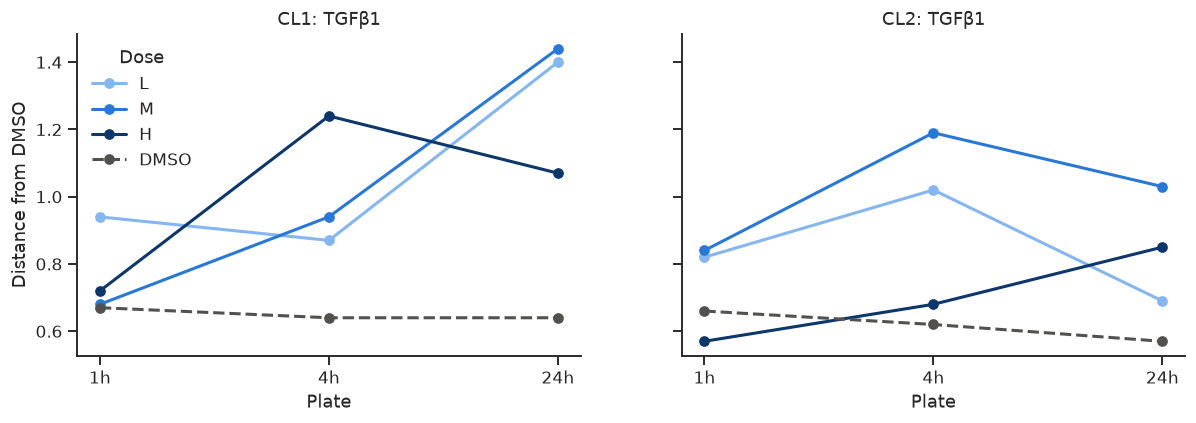

In [28]:
distances = (
    well_info.with_columns(pl.Series("distance", np.median(np.abs(selected_matrix), axis=1)))
    .group_by("plate", "cell_line", "treatment")
    .agg(pl.col("distance").median().round(2), pl.len().alias("wells"))
)
ligand_view = (
    distances.filter(pl.col("treatment").str.contains("TGFb1|IL6|DMSO"))
    .pivot(on="plate", index=["cell_line", "treatment"], values="distance")
    .select("cell_line", "treatment", *plate_order)
    .sort("cell_line", "treatment")
)
print(ligand_view)
print(
    replicates.filter(pl.col("is_ligand"))
    .with_columns(pl.when(pl.col("correlation") > pl.col("null_line")).then(pl.lit("yes")).otherwise(pl.lit("no")).alias("passed"))
    .pivot(on="plate", index=["cell_line", "treatment"], values="passed")
    .select("cell_line", "treatment", *plate_order)
    .sort("cell_line", "treatment")
)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
dose_order = ["L", "M", "H"]
dose_shades = {"L": "#86b6ef", "M": "#2a78d6", "H": "#0d366b"}
for ax, line in zip(axes, ["CL1", "CL2"]):
    for dose in dose_order:
        values = [
            distances.filter((pl.col("cell_line") == line) & (pl.col("plate") == t) & (pl.col("treatment") == f"TGFb1_{dose}"))["distance"].item()
            for t in plate_order
        ]
        ax.plot(plate_order, values, marker="o", lw=2, color=dose_shades[dose], label=dose)
    control = [
        distances.filter((pl.col("cell_line") == line) & (pl.col("plate") == t) & (pl.col("treatment") == "DMSO"))["distance"].item()
        for t in plate_order
    ]
    ax.plot(plate_order, control, marker="o", lw=2, color="#52514e", ls="--", label="DMSO")
    ax.set(title=f"{line}: TGFβ1", xlabel="Plate")
axes[0].set_ylabel("Distance from DMSO")
axes[0].legend(title="Dose", frameon=False)
plt.show()

In [29]:
# which part of the cell carries the replicate signal?
feature_groups = {
    "Nuclei": [i for i, n in zip(selected, selected_names) if n.startswith("Nuclei_")],
    "Cells": [i for i, n in zip(selected, selected_names) if n.startswith("Cells_")],
    "Cytoplasm": [i for i, n in zip(selected, selected_names) if n.startswith("Cytoplasm_")],
}
rows = []
for name, columns in feature_groups.items():
    for line in ["CL1", "CL2"]:
        passed, total = 0, 0
        for time in plate_order:
            part = indexed.filter((pl.col("plate") == time) & (pl.col("cell_line") == line))
            results, _ = replicate_test(part, well_matrix[:, columns])
            passed += sum(r["correlation"] > r["null_line"] for r in results)
            total += len(results)
        rows.append({"features": name, "n_features": len(columns), "cell_line": line, "pct_replicating": round(100 * passed / total, 1)})
print(pl.DataFrame(rows).sort("features", "cell_line"))

shape: (6, 4)
┌───────────┬────────────┬───────────┬─────────────────┐
│ features  ┆ n_features ┆ cell_line ┆ pct_replicating │
│ ---       ┆ ---        ┆ ---       ┆ ---             │
│ str       ┆ i64        ┆ str       ┆ f64             │
╞═══════════╪════════════╪═══════════╪═════════════════╡
│ Cells     ┆ 259        ┆ CL1       ┆ 33.3            │
│ Cells     ┆ 259        ┆ CL2       ┆ 44.4            │
│ Cytoplasm ┆ 301        ┆ CL1       ┆ 30.2            │
│ Cytoplasm ┆ 301        ┆ CL2       ┆ 38.1            │
│ Nuclei    ┆ 280        ┆ CL1       ┆ 36.5            │
│ Nuclei    ┆ 280        ┆ CL2       ┆ 34.9            │
└───────────┴────────────┴───────────┴─────────────────┘


**What we found**

**TGFβ1 partly passes as a positive control, and IL6 shows no clear effect.**

- **TGFβ1 is reproducible:** 12 of its 18 tests pass (plate, cell line and dose together). Its distance from DMSO reaches 1.44, compared with 0.57 to 0.67 for controls.
- **Time:** the pattern only partly fits the prediction. In CL1, the low and medium doses are furthest from DMSO at 24h, but the high dose peaks at 4h. In CL2, the low and medium doses peak at 4h.
- **Dose:** we did not see the expected dose response. In CL2, the high dose has the smallest effect at 1h and 4h, and it reaches only 0.85 at 24h. This does not support the prediction. It may be a biological effect, or a problem with the high-dose wells, or noise, because each dose has only 3 wells. It deserves a check after the new run.
- **IL6:** only 1 of 18 tests passes, which is what chance alone would give. IL6 may have no visible effect on these cells, or the profiles may not be able to detect it. We cannot tell these apart.
- **Part of the cell:** Nuclei, Cells and Cytoplasm features perform about equally (30 to 44%). No single group fails, so none of them can be dropped.

We cannot say from this data that TGFβ1 caused an epithelial-mesenchymal transition. We only see that the profiles change in a reproducible way.

## 10. Scorecard

This table collects every check. For checks measured per plate or cell line, it shows the worst result.

In [30]:
results_table = pl.DataFrame(scorecard)
rank = {"PASS": 0, "WARN": 1, "FAIL": 2}
worst = (
    results_table.with_columns(
        pl.col("grade").replace_strict(rank, return_dtype=pl.Int64).alias("rank"),
        # the worst value is the highest for "lower is better" checks and the lowest for the others
        pl.when(pl.col("check").is_in([k for k, v in limits.items() if v[2] == "low"]))
        .then(pl.col("value"))
        .otherwise(-pl.col("value"))
        .alias("badness"),
    )
    .sort("badness", descending=True)
    .group_by("check", maintain_order=True)
    .agg(
        pl.col("value").first().alias("worst_value"),
        pl.col("group").first().alias("worst_group"),
        pl.col("grade").first(),
        (pl.col("grade") == "PASS").sum().alias("groups_passed"),
        pl.len().alias("groups"),
    )
)
order = {name: i for i, name in enumerate(limits)}
worst = worst.with_columns(pl.col("check").replace_strict(order, return_dtype=pl.Int64).alias("order")).sort("order").drop("order")
print(worst)

results_table.write_csv(cache_dir / "qc_scorecard.csv")

shape: (13, 6)
┌───────────────────────────────────────────────┬─────────────┬─────────────┬───────┬───────────────┬────────┐
│ check                                         ┆ worst_value ┆ worst_group ┆ grade ┆ groups_passed ┆ groups │
│ ---                                           ┆ ---         ┆ ---         ┆ ---   ┆ ---           ┆ ---    │
│ str                                           ┆ f64         ┆ str         ┆ str   ┆ u32           ┆ u32    │
╞═══════════════════════════════════════════════╪═════════════╪═════════════╪═══════╪═══════════════╪════════╡
│ Missing sites (%)                             ┆ 0.03        ┆ All         ┆ PASS  ┆ 1             ┆ 1      │
│ Sites out of focus (%)                        ┆ 1.64        ┆ 24h CL2     ┆ PASS  ┆ 6             ┆ 6      │
│ Sites with over 1% saturated DNA pixels (%)   ┆ 0.2         ┆ 1h          ┆ PASS  ┆ 3             ┆ 3      │
│ Brightness change across the field (max/min)  ┆ 1.09        ┆ AGP         ┆ PASS  ┆ 5          

## 11. Decision

### Verdict

**We reject H0: change the CellProfiler settings and run all 3 plates again.** The rule from the start of this notebook is met. Five of the 7 segmentation checks fail in at least half of the groups (too little DNA, cut nuclei, AGP signal, cytoplasm and solidity), and the DNA positive control supports the cause (section 7.4).

| Part of the data | Status | Reason |
|---|---|---|
| Images (focus, saturation, illumination) | Good, no new imaging needed | All checks pass |
| Nuclei segmentation | **Must change** | 18 to 54% of objects are pieces of a nucleus |
| Cell outlines | **Must change** | Ragged, and they miss up to 46% of the AGP signal |
| Features | Fine | They will improve once the outlines improve |
| Biological signal | Present | TGFβ1 replicates, and the DMSO negative control passes |

### Settings to change in `2_analysis.cppipe`

These are **starting values**. We chose them from the results above, but **we have not tested them in CellProfiler**.

| Module | Setting | Now | Try | Why |
|---|---|---|---|---|
| IdentifyPrimaryObjects | Typical diameter | 20, 80 | **30, 120** | Real nuclei reach about 100 pixels. The higher minimum also raises the automatic blur and spot distance from about 13 to about 20 pixels, so large nuclei are cut less often. |
| IdentifyPrimaryObjects | Method to distinguish clumped objects | Intensity | **Shape** | Uneven DNA staining creates false bright spots. Shape uses the outline, and most nuclei here are smooth and round. |
| IdentifyPrimaryObjects | Method to draw dividing lines | Intensity | **Shape** | Same reason. |
| IdentifySecondaryObjects | Method | Watershed - Gradient | **Propagation** | It should give smoother outlines. The pipeline already holds a regularization value of 0.05, which only Propagation uses. |
| IdentifySecondaryObjects | Threshold smoothing scale | 0 | **1.3488** | Without smoothing, the cell edge follows pixel noise. |
| IdentifySecondaryObjects | Threshold correction factor | 1.0 | **0.7, then 0.5** | A lower threshold includes the dim cytoplasm. If it adds too much background, try the log transform setting instead. |

**Trade-off of the new minimum diameter.** About 1 to 5% of objects, after joining, are smaller than 30 pixels. Some of them may be real small nuclei, not debris. If the new run loses too many, try a minimum of 25.

**Two notes on the current pipeline.**

- The note in IdentifyPrimaryObjects says "Otsu", but the setting is Minimum Cross-Entropy. We see no sign that this causes a problem, but the note should match the setting.
- "Maximum number of objects" is 500, with the setting "Continue". It sets no real limit: many sites have more than 500 nuclei.

### How to test the new settings

1. Run the new settings on a small test set. `project-data/test-images` is not enough on its own: it has only 2 wells per plate, and on the 1h plate these are CL1 wells (A02 and A03). Add CL2 wells, because CL2 has the largest problem. The wells in section 7.1 (I17, B22 and O17) are a good start.
2. Compare the outlines by eye, as in section 7.1.
3. Run the full plates when the outlines look right.
4. Delete `data/qc-cache` and run this notebook again. The new run has passed when CL2 shows two clear DNA peaks, and the cut, AGP and solidity checks reach at least WARN.

### Other actions, not in CellProfiler

- **Confirm the cell lines.** Find out which line is CL1 and which is CL2, and correct the `MDA-MB-231_wt_ko` value in the records.
- **Keep the exposure difference in mind.** Compare each well with the DMSO wells of its own plate, and never compare raw intensities with the 24h plate.
- **Check the 24h plate handling.** Find out why CL1 has patches with few cells on that plate.
- **Account for cell count** in the later analysis, and filter wells with few cells.
- **Check the TGFβ1 high-dose wells,** because their weak effect in CL2 is unexpected.

### What this notebook cannot show

- Section 7.4 and the AGP check use 72 images from control wells, not all images. Treated wells may behave differently.
- Our test for a cut nucleus uses a shape rule, which can sometimes join two real, tightly touching nuclei.
- The AGP check assumes that dim red signal outside the outlines is cytoplasm. Someone who knows these cells should confirm this.
- We cannot separate cell line from plate side, or time from exposure, because of the plate layout and imaging settings.